## 1. Install missing libraries and import required packages

The first code cell imports plotting, preprocessing, imbalance-handling, classification, cross-validation, and multilingual sentence-embedding libraries. A package is installed only if it is missing.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "imblearn": "imbalanced-learn",
    "lightgbm": "lightgbm",
    "sentence_transformers": "sentence-transformers",
    "joblib": "joblib",
}
missing_packages = [pip_name for module, pip_name in REQUIRED_PACKAGES.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    print("Installing missing packages:", missing_packages)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])
    except Exception as exc:
        raise RuntimeError(
            "Package installation failed. Verify that Google Colab has internet access "
            "and rerun the first cell. Missing: " + ", ".join(missing_packages)
        ) from exc

import hashlib
import json
import os
import shutil
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sentence_transformers import SentenceTransformer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
    make_scorer,
)
from sklearn.model_selection import (StratifiedKFold, cross_validate, train_test_split, ParameterSampler)
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.base import clone
from scipy.stats import randint, loguniform, uniform
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
print("Task 2 libraries imported successfully.")
print("scikit-learn:", __import__("sklearn").__version__,
      "| imbalanced-learn:", __import__("imblearn").__version__,
      "| LightGBM:", __import__("lightgbm").__version__)

Task 2 libraries imported successfully.
scikit-learn: 1.6.1 | imbalanced-learn: 0.14.2 | LightGBM: 4.6.0


## 2. Configure input data, encoder, saving and optimization

Change `DATA_PATH`, `TARGET_COLUMN`, `POSITIVE_CLASS`, `N_SEARCH_PER_MODEL` or the model name here. This notebook stores Task 2 results separately from Task 1. Default task-specific paths and filenames prevent overwriting Task 1.

In [2]:
IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    try:
        from google.colab import drive, files
        drive.mount("/content/drive")
    except Exception as exc:
        raise RuntimeError("Could not mount Google Drive. Reconnect and authorize access.") from exc

DEFAULT_DATA_PATH = (
    "/content/drive/MyDrive/Recruitment_E4_Only/original_recruitment_data.csv"
    if IS_COLAB else "staffit_synthetic_matching_3000_consistent.csv"
)
DATA_PATH = os.environ.get("TASK2_DATA_PATH", DEFAULT_DATA_PATH)
OUTPUT_DIR = Path(os.environ.get(
    "TASK2_OUTPUT_DIR",
    "/content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results"
    if IS_COLAB else "Task_2_Optimized_Results"
))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COLUMN = "TARGET"
POSITIVE_CLASS = 1
TEST_SIZE = 0.20
OVERSAMPLING_RATIO = 1.0  # baseline (1 positive per 1 negative)
N_SEARCH_PER_MODEL = int(os.environ.get("TASK2_N_SEARCH", "8"))
if N_SEARCH_PER_MODEL < 1:
    raise ValueError("TASK2_N_SEARCH must be at least 1")
BALANCE_STRATEGIES = {
    "none": None,
    "oversample_0.5": 0.5,   # one positive for every two negatives
    "oversample_1.0": 1.0,   # equal positive/negative counts
}
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)
RANDOM_STATE = 42

# Keep the *actual* 10 numerical attributes used by Task 1.
NUMERIC_MAP = {
    "コミュニケーションスキル点数": "Communication_Skill_Score",
    "オーダー必須設定数のマッチ割合": "Job_Required_Criteria_Match_Ratio",
    "スタッフ必須設定数のマッチ割合": "Applicant_Required_Criteria_Match_Ratio",
    "求人職種_経験職種_直近3社_BM25": "Job_Experience_BM25_Score",
    "業務内容補足情報_職歴情報_直近3社_JACCARD": "Job_Work_History_Jaccard_Score",
    "職歴数": "Total_Job_History_Count",
    "直近3年での職歴数": "Job_History_Count_Last_3_Years",
    "最初に働き始めた年から今までの年数あたりの職歴数": "Job_Changes_Per_Career_Year",
    "JOB_EXP_MATCH_SCORE": "JOB_EXP_MATCH_SCORE",
    "SKILL_MATCH_SCORE": "SKILL_MATCH_SCORE",
}
NUMERIC_FEATURES = list(NUMERIC_MAP.values())
ID_COLUMNS = ["Recruitment_ID", "Applicant_ID"]
TEXT_COLUMNS = ["Job", "Choice Point", "Skills"]
SEMANTIC_FEATURES = [
    "Job_Skills_Cosine", "Job_Choice_Cosine", "Choice_Skills_Cosine",
    "Mean_Cosine", "Max_Cosine", "Min_Cosine",
]
TASK2_FEATURES = [*NUMERIC_FEATURES, *SEMANTIC_FEATURES]
ENCODER_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
# A matching prior Task 2 / earlier multilingual cache avoids re-encoding.
LOCAL_SEMANTIC_CACHE = OUTPUT_DIR / "Task_2_semantic_cache.joblib"
PREVIOUS_SEMANTIC_CACHE = (
    Path("/content/drive/MyDrive/Recruitment_E4_Only/E4_multilingual_features.joblib")
    if IS_COLAB else Path("/mnt/data/E4_multilingual_features.joblib")
)
BATCH_SIZE = 32

# Descriptive working translations: confirm precise meanings with the dataset provider.
TRANSLATION_TO_CONFIRM = {
    "オーダー必須設定数のマッチ割合": "Does 'order' refer to a job request?",
    "スタッフ必須設定数のマッチ割合": "Does 'staff' mean an applicant's stated criteria?",
    "求人職種_経験職種_直近3社_BM25": "Confirm scope of the 'last three companies' BM25 metric.",
    "業務内容補足情報_職歴情報_直近3社_JACCARD": "Confirm the source fields used for this Jaccard metric.",
}

def save_csv(frame, filename):
    path = OUTPUT_DIR / filename
    frame.to_csv(path, index=False, encoding="utf-8-sig")
    print("SAVED:", path)
    return path

def save_json(content, filename):
    path = OUTPUT_DIR / filename
    with open(path, "w", encoding="utf-8") as f:
        json.dump(content, f, indent=2, ensure_ascii=False, default=str)
    print("SAVED:", path)
    return path

def save_plot(filename):
    path = OUTPUT_DIR / filename
    plt.savefig(path, dpi=180, bbox_inches="tight")
    print("SAVED:", path)
    return path

print("Dataset path:", DATA_PATH)
print("Results folder:", OUTPUT_DIR.resolve())
print("Positive target label:", POSITIVE_CLASS)
print("Baseline oversampling ratio:", OVERSAMPLING_RATIO)
print("Tuning trials per model:", N_SEARCH_PER_MODEL, "x", len(BALANCE_STRATEGIES), "imbalance strategies x 5 folds")
print("Encoder:", ENCODER_MODEL)
print("Task 2 feature count:", len(TASK2_FEATURES))


Mounted at /content/drive
Dataset path: /content/drive/MyDrive/Recruitment_E4_Only/original_recruitment_data.csv
Results folder: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results
Positive target label: 1
Baseline oversampling ratio: 1.0
Tuning trials per model: 8 x 3 imbalance strategies x 5 folds
Encoder: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Task 2 feature count: 16


## 3. Load and inspect the original Japanese dataset

The supplied CSV is read directly; `head()`, all original column names, data types, missing values and exact duplicate counts are displayed in the following cells. An unchanged CSV copy is saved for reproducibility.

In [3]:
dataset_path = Path(DATA_PATH).expanduser()
if not dataset_path.is_file():
    if IS_COLAB:
        print("Configured CSV not found:", dataset_path)
        print("Upload the original recruitment dataset (.csv) now.")
        uploaded = files.upload()
        csv_names = [filename for filename in uploaded if filename.lower().endswith(".csv")]
        if len(csv_names) != 1:
            raise FileNotFoundError(
                "Upload exactly one CSV file, or set DATA_PATH to an existing CSV."
            )
        dataset_path = Path(csv_names[0]).resolve()
    else:
        candidates = [
            Path("staffit_synthetic_matching_3000_consistent(2).csv"),
            Path("/mnt/data/staffit_synthetic_matching_3000_consistent(2).csv"),
            Path("/mnt/data/staffit_synthetic_matching_3000_consistent.csv"),
        ]
        found = next((p for p in candidates if p.is_file()), None)
        if found is None:
            raise FileNotFoundError(
                f"CSV not found: {dataset_path}. Change DATA_PATH in Section 2."
            )
        dataset_path = found.resolve()
try:
    raw_df = pd.read_csv(dataset_path)
except Exception as exc:
    raise RuntimeError(f"Unable to read CSV at {dataset_path}: {exc}") from exc

if raw_df.empty:
    raise ValueError("The supplied CSV is empty.")

print("Loaded:", dataset_path)
print("Dataset shape:", raw_df.shape)
print("First 5 rows:")
display(raw_df.head(5))

# Make a permanent input copy for reproducibility (the data remains unchanged).
original_copy_path = OUTPUT_DIR / "input_dataset_original.csv"
if dataset_path.resolve() != original_copy_path.resolve():
    shutil.copy2(dataset_path, original_copy_path)
print("SAVED:", original_copy_path)

Configured CSV not found: /content/drive/MyDrive/Recruitment_E4_Only/original_recruitment_data.csv
Upload the original recruitment dataset (.csv) now.


Saving staffit_synthetic_matching_3000_consistent.csv to staffit_synthetic_matching_3000_consistent.csv
Loaded: /content/staffit_synthetic_matching_3000_consistent.csv
Dataset shape: (3000, 16)
First 5 rows:


,Recruitment_ID,Applicant_ID,コミュニケーションスキル点数,オーダー必須設定数のマッチ割合,スタッフ必須設定数のマッチ割合,求人職種_経験職種_直近3社_BM25,業務内容補足情報_職歴情報_直近3社_JACCARD,職歴数,直近3年での職歴数,最初に働き始めた年から今までの年数あたりの職歴数,JOB_EXP_MATCH_SCORE,SKILL_MATCH_SCORE,TARGET,Job,Choice Point,Skills
0,REC0028,APP0036,63,0.149,0.660,2.168,0.205,8,2,0.333,0.010,0.360,0,倉庫・物流の募集。入荷検品、ピッキング、梱包、出荷指示を担当。新規プロジェクトでの勤務。募集...,安全管理、作業の正確さ、倉庫業務の経験を重視。応募条件は実務経験1年以上。募集枠028。,医療事務を経験し、受付、会計、診療報酬データ入力が可能。実務経験2年程度。繁忙期の対応経験あ...
1,REC0013,APP0003,82,0.010,0.346,0.081,0.359,2,1,0.500,0.224,0.070,0,カスタマーサポートの募集。顧客の問い合わせ受付、対応履歴記録、担当部署への引継ぎを担当。新規...,傾聴力、CRM入力、落ち着いた顧客対応を重視。応募条件は実務経験1年以上。募集枠013。,工場で外観検査を2年間経験。ノギス測定と検査記録の作成が可能。
2,REC0017,APP0076,90,0.444,0.580,4.770,0.329,9,1,0.450,0.457,0.397,0,Web開発の募集。Webアプリの実装、コードレビュー、不具合修正を担当。小規模チームでの勤務...,PythonまたはJavaScript、Git、チーム開発を重視。応募条件は実務経験3年以上...,物流倉庫での検品、ピッキング、ハンディ端末操作が可能。実務経験4年程度。繁忙期の対応経験あり...
3,REC0064,APP0053,80,0.267,0.828,1.675,0.064,7,2,0.467,0.053,0.338,0,品質検査の募集。製品の外観検査、寸法測定、検査記録の作成を担当。複数部署連携での勤務。募集枠...,測定機器の使用、品質基準の理解、記録管理を重視。応募条件は未経験可。募集枠064。,介護スタッフを経験し、生活支援、介護記録、チーム連携が可能。実務経験4年程度。業務マニュアル...
4,REC0062,APP0033,69,0.024,0.932,1.470,0.016,6,1,1.000,0.010,0.010,0,一般事務の募集。受発注入力、請求書確認、Excel集計、電話とメール対応を担当。小規模チーム...,Excel、事務の正確性、社内調整を重視。応募条件は実務経験3年以上。募集枠062。,Web開発を経験し、Python、JavaScript、Gitを利用可能。実務経験1年程度。...


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/input_dataset_original.csv


## 4. Audit column types, missing values and duplicates

In [4]:
print("Shape:", raw_df.shape)
print("\nOriginal columns:")
for idx, col in enumerate(raw_df.columns, 1):
    print(f"{idx:2d}. {col}")
print("\nData types:")
print(raw_df.dtypes.to_string())
print("\nMissing values by column:")
print(raw_df.isna().sum().to_string())
print("\nExact duplicate rows:", int(raw_df.duplicated().sum()))
if set(ID_COLUMNS).issubset(raw_df.columns):
    print("Duplicate Recruitment_ID/Applicant_ID pairs:",
          int(raw_df.duplicated(subset=ID_COLUMNS).sum()))

audit_table = pd.DataFrame({
    "Original_Column": raw_df.columns,
    "Data_Type": [str(x) for x in raw_df.dtypes],
    "Missing_Count": raw_df.isna().sum().to_numpy(),
    "Unique_Count": raw_df.nunique(dropna=False).to_numpy(),
})
display(audit_table)
save_csv(audit_table, "data_audit_columns.csv")
save_json({
    "rows": len(raw_df), "columns": len(raw_df.columns),
    "exact_duplicate_rows": int(raw_df.duplicated().sum()),
    "duplicate_id_pairs": (int(raw_df.duplicated(subset=ID_COLUMNS).sum())
                           if set(ID_COLUMNS).issubset(raw_df.columns) else None),
    "data_sha256": hashlib.sha256(dataset_path.read_bytes()).hexdigest(),
}, "data_audit_summary.json")

Shape: (3000, 16)

Original columns:
 1. Recruitment_ID
 2. Applicant_ID
 3. コミュニケーションスキル点数
 4. オーダー必須設定数のマッチ割合
 5. スタッフ必須設定数のマッチ割合
 6. 求人職種_経験職種_直近3社_BM25
 7. 業務内容補足情報_職歴情報_直近3社_JACCARD
 8. 職歴数
 9. 直近3年での職歴数
10. 最初に働き始めた年から今までの年数あたりの職歴数
11. JOB_EXP_MATCH_SCORE
12. SKILL_MATCH_SCORE
13. TARGET
14. Job
15. Choice Point
16. Skills

Data types:
Recruitment_ID                 object
Applicant_ID                   object
コミュニケーションスキル点数                  int64
オーダー必須設定数のマッチ割合               float64
スタッフ必須設定数のマッチ割合               float64
求人職種_経験職種_直近3社_BM25           float64
業務内容補足情報_職歴情報_直近3社_JACCARD    float64
職歴数                             int64
直近3年での職歴数                       int64
最初に働き始めた年から今までの年数あたりの職歴数      float64
JOB_EXP_MATCH_SCORE           float64
SKILL_MATCH_SCORE             float64
TARGET                          int64
Job                            object
Choice Point                   object
Skills                         object

Missing values by column:
Recruitment_ID       

,Original_Column,Data_Type,Missing_Count,Unique_Count
0,Recruitment_ID,object,0,75
1,Applicant_ID,object,0,80
2,コミュニケーションスキル点数,int64,0,33
3,オーダー必須設定数のマッチ割合,float64,0,792
4,スタッフ必須設定数のマッチ割合,float64,0,756
5,求人職種_経験職種_直近3社_BM25,float64,0,2358
6,業務内容補足情報_職歴情報_直近3社_JACCARD,float64,0,735
7,職歴数,int64,0,9
8,直近3年での職歴数,int64,0,4
9,最初に働き始めた年から今までの年数あたりの職歴数,float64,0,36


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/data_audit_columns.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/data_audit_summary.json


PosixPath('/content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/data_audit_summary.json')

## 5. Translate existing Japanese numerical headers into English

Only the column headers are renamed, never the source values. Uncertain domain-specific translations are flagged for confirmation.

In [5]:
missing_numeric_headers = [col for col in NUMERIC_MAP if col not in raw_df.columns]
if missing_numeric_headers:
    raise ValueError(
        "Missing expected original numerical columns: " +
        ", ".join(missing_numeric_headers)
    )
if TARGET_COLUMN not in raw_df.columns:
    raise KeyError(
        f"Target column {TARGET_COLUMN!r} is missing. "
        f"Available columns: {list(raw_df.columns)}"
    )

df = raw_df.rename(columns=NUMERIC_MAP).copy()
translation_table = pd.DataFrame({
    "Original_Japanese_Column": list(NUMERIC_MAP),
    "English_Column": list(NUMERIC_MAP.values()),
    "Translation_Status": [
        "Confirm domain meaning" if src in TRANSLATION_TO_CONFIRM else "Working label"
        for src in NUMERIC_MAP
    ],
    "Clarification_Needed": [TRANSLATION_TO_CONFIRM.get(src, "") for src in NUMERIC_MAP],
})
print("Original and translated names:")
display(translation_table)
print("\nRenamed data types:")
print(df[NUMERIC_FEATURES].dtypes.to_string())
save_csv(translation_table, "column_translation_map.csv")

# Verify no values changed by translation.
for original, english in NUMERIC_MAP.items():
    if not raw_df[original].equals(df[english]):
        raise AssertionError(f"Feature values changed unexpectedly: {original}")
print("Verification passed: translated headers, original values preserved.")

Original and translated names:


,Original_Japanese_Column,English_Column,Translation_Status,Clarification_Needed
0,コミュニケーションスキル点数,Communication_Skill_Score,Working label,
1,オーダー必須設定数のマッチ割合,Job_Required_Criteria_Match_Ratio,Confirm domain meaning,Does 'order' refer to a job request?
2,スタッフ必須設定数のマッチ割合,Applicant_Required_Criteria_Match_Ratio,Confirm domain meaning,Does 'staff' mean an applicant's stated criteria?
3,求人職種_経験職種_直近3社_BM25,Job_Experience_BM25_Score,Confirm domain meaning,Confirm scope of the 'last three companies' BM...
4,業務内容補足情報_職歴情報_直近3社_JACCARD,Job_Work_History_Jaccard_Score,Confirm domain meaning,Confirm the source fields used for this Jaccar...
5,職歴数,Total_Job_History_Count,Working label,
6,直近3年での職歴数,Job_History_Count_Last_3_Years,Working label,
7,最初に働き始めた年から今までの年数あたりの職歴数,Job_Changes_Per_Career_Year,Working label,
8,JOB_EXP_MATCH_SCORE,JOB_EXP_MATCH_SCORE,Working label,
9,SKILL_MATCH_SCORE,SKILL_MATCH_SCORE,Working label,



Renamed data types:
Communication_Skill_Score                    int64
Job_Required_Criteria_Match_Ratio          float64
Applicant_Required_Criteria_Match_Ratio    float64
Job_Experience_BM25_Score                  float64
Job_Work_History_Jaccard_Score             float64
Total_Job_History_Count                      int64
Job_History_Count_Last_3_Years               int64
Job_Changes_Per_Career_Year                float64
JOB_EXP_MATCH_SCORE                        float64
SKILL_MATCH_SCORE                          float64
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/column_translation_map.csv
Verification passed: translated headers, original values preserved.


## 6. Check the target and original class imbalance

The **positive class is the matching class (`TARGET = 1`)**. We visualize the source prevalence, not the balanced training distribution. Imbalanced datasets need precision, recall, F1, ROC-AUC and balanced accuracy, rather than accuracy alone.

,Class,Count,Percent
0,Negative (0),2850,95.0
1,Positive (1),150,5.0


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/original_class_distribution.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/original_class_pie.png


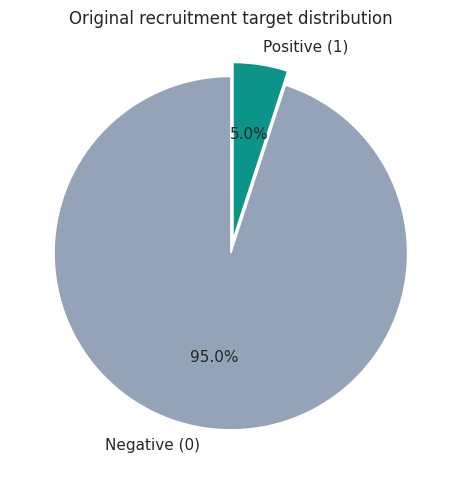

In [6]:
target_values = set(pd.Series(df[TARGET_COLUMN]).dropna().unique().tolist())
if df[TARGET_COLUMN].isna().any():
    raise ValueError("Target labels contain missing values. Resolve these before training.")
if target_values != {0, 1}:
    raise ValueError(
        f"This notebook expects binary TARGET values {{0, 1}}; found {target_values}."
    )
if POSITIVE_CLASS not in target_values:
    raise ValueError(f"POSITIVE_CLASS={POSITIVE_CLASS!r} is not present in the target.")

# Normalize the configured positive class to 1 for metrics and probability indexing.
y_all = (df[TARGET_COLUMN] == POSITIVE_CLASS).astype(int)
class_counts = y_all.value_counts().reindex([0, 1], fill_value=0)
class_table = pd.DataFrame({
    "Class": ["Negative (0)", "Positive (1)"],
    "Count": class_counts.to_numpy(),
    "Percent": class_counts.to_numpy() / len(y_all) * 100,
})
display(class_table)
save_csv(class_table, "original_class_distribution.csv")

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(class_table["Count"], labels=class_table["Class"],
       autopct="%1.1f%%", startangle=90, explode=(0, 0.08),
       colors=["#94A3B8", "#0D9488"], textprops={"fontsize": 11})
ax.set_title("Original recruitment target distribution")
plt.tight_layout()
save_plot("original_class_pie.png")
plt.show()

## 7. Audit ten original numerical features

Remove `Recruitment_ID` and `Applicant_ID` from model inputs; keep them only for group-overlap analysis. We first audit the ten source numerical features; six frozen-transformer similarities are added in the next two sections. The engineered scores `SKILL_MATCH_SCORE` and `JOB_EXP_MATCH_SCORE` need a label-generation audit to rule out target leakage.

In [7]:
missing_selected = [c for c in NUMERIC_FEATURES if c not in df.columns]
if missing_selected:
    raise ValueError(f"Missing original numerical features: {missing_selected}")
X_all = df[NUMERIC_FEATURES].copy()
for col in X_all.select_dtypes(include=["object", "string"]).columns:
    converted = pd.to_numeric(X_all[col], errors="coerce")
    if converted.notna().sum() > 0 and converted.notna().sum() >= X_all[col].notna().sum() * 0.95:
        X_all[col] = converted

numeric_columns = X_all.select_dtypes(include="number").columns.tolist()
categorical_columns = [c for c in X_all if c not in numeric_columns]
if X_all[numeric_columns].isna().all().any():
    raise ValueError("At least one numerical feature contains only missing values.")
if not numeric_columns and not categorical_columns:
    raise ValueError("No usable model features were selected.")

print("Selected input features:", X_all.columns.tolist())
print("Numerical:", numeric_columns)
print("Categorical (one-hot encoded if present):", categorical_columns)
print("Excluded identifiers:", [c for c in ID_COLUMNS if c in df.columns])
print("Japanese text will be converted into semantic features:", [c for c in TEXT_COLUMNS if c in df])
print("Selected-feature missing counts:", X_all.isna().sum().to_dict())
print("Duplicate numerical feature vectors:", int(X_all.duplicated().sum()))
print("Possible engineered-label leakage features: SKILL_MATCH_SCORE, JOB_EXP_MATCH_SCORE")

feature_audit = pd.DataFrame({
    "Feature": X_all.columns,
    "Type": [str(X_all[c].dtype) for c in X_all],
    "Missing": [int(X_all[c].isna().sum()) for c in X_all],
    "Unique_Values": [int(X_all[c].nunique(dropna=False)) for c in X_all],
})
display(feature_audit)
save_csv(feature_audit, "numeric_feature_audit.csv")

Selected input features: ['Communication_Skill_Score', 'Job_Required_Criteria_Match_Ratio', 'Applicant_Required_Criteria_Match_Ratio', 'Job_Experience_BM25_Score', 'Job_Work_History_Jaccard_Score', 'Total_Job_History_Count', 'Job_History_Count_Last_3_Years', 'Job_Changes_Per_Career_Year', 'JOB_EXP_MATCH_SCORE', 'SKILL_MATCH_SCORE']
Numerical: ['Communication_Skill_Score', 'Job_Required_Criteria_Match_Ratio', 'Applicant_Required_Criteria_Match_Ratio', 'Job_Experience_BM25_Score', 'Job_Work_History_Jaccard_Score', 'Total_Job_History_Count', 'Job_History_Count_Last_3_Years', 'Job_Changes_Per_Career_Year', 'JOB_EXP_MATCH_SCORE', 'SKILL_MATCH_SCORE']
Categorical (one-hot encoded if present): []
Excluded identifiers: ['Recruitment_ID', 'Applicant_ID']
Japanese text will be converted into semantic features: ['Job', 'Choice Point', 'Skills']
Selected-feature missing counts: {'Communication_Skill_Score': 0, 'Job_Required_Criteria_Match_Ratio': 0, 'Applicant_Required_Criteria_Match_Ratio': 0, 'J

,Feature,Type,Missing,Unique_Values
0,Communication_Skill_Score,int64,0,33
1,Job_Required_Criteria_Match_Ratio,float64,0,792
2,Applicant_Required_Criteria_Match_Ratio,float64,0,756
3,Job_Experience_BM25_Score,float64,0,2358
4,Job_Work_History_Jaccard_Score,float64,0,735
5,Total_Job_History_Count,int64,0,9
6,Job_History_Count_Last_3_Years,int64,0,4
7,Job_Changes_Per_Career_Year,float64,0,36
8,JOB_EXP_MATCH_SCORE,float64,0,777
9,SKILL_MATCH_SCORE,float64,0,773


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/numeric_feature_audit.csv


PosixPath('/content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/numeric_feature_audit.csv')

## 8. Understanding multilingual sentence embeddings (simple mathematics)

Our source text is **Japanese**; we do not translate it to English in Task 2. The frozen multilingual MiniLM encoder converts each sentence into a vector of **384 numbers**:

\[
e_J = f_{\mathrm{MiniLM}}(\mathrm{Job}) \in \mathbb{R}^{384}
\]

Likewise, \(e_C\) represents `Choice Point` and \(e_S\) represents `Skills`.

**Simple interpretation:** The 384 numbers describe the sentence in a numerical space. Semantically related descriptions are expected to have vectors pointing in similar directions. The model is **pretrained**; no new supervised encoder training or fine-tuning occurs here.

To compare two vectors, we calculate **cosine similarity**:

\[
\operatorname{cos}(A,B)=\frac{A\cdot B}{\|A\|\,\|B\|}
\]

Because our encoder normalizes vectors, this reduces to a simple dot product:

\[
\operatorname{cos}(A,B)= A\cdot B
\]

Cosine similarity lies between **-1 and +1**; larger values generally indicate greater semantic alignment. It is **not** a probability of a good recruitment match.

**Embedding workflow:** Japanese text -> MiniLM (384-dimensional vector) -> cosine similarity -> six numerical features.

In [8]:
# Verify the three original Japanese fields. Nothing here reads or fits TARGET.
missing_text = [c for c in TEXT_COLUMNS if c not in df.columns]
if missing_text:
    raise ValueError("Task 2 needs the source text columns: " + repr(missing_text))
text_frame = df[TEXT_COLUMNS].fillna("").astype(str)
text_missing = df[TEXT_COLUMNS].isna().sum()
if text_missing.any():
    print("CAUTION: Missing text values are replaced with empty strings:", text_missing.to_dict())
print("Unique Japanese text values:", text_frame.nunique().to_dict())
print("Example source texts (truncated):")
display(text_frame.head(3).apply(lambda col: col.str.slice(0, 100)))

current_sha = hashlib.sha256(dataset_path.read_bytes()).hexdigest()

def valid_semantic_cache(path):
    """Accept only same original input bytes, encoder name and expected features."""
    if not path.is_file():
        return None
    try:
        contents = joblib.load(path)
        if not isinstance(contents, dict):
            return None
        if contents.get("sha256") != current_sha or contents.get("model_name") != ENCODER_MODEL:
            return None
        source = contents.get("features")
        if not isinstance(source, pd.DataFrame) or len(source) != len(df):
            return None
        if not set(SEMANTIC_FEATURES).issubset(source.columns):
            return None
        selected = source[SEMANTIC_FEATURES].reset_index(drop=True).astype(float)
        if not np.isfinite(selected.to_numpy()).all():
            return None
        if np.any(np.abs(selected.to_numpy()) > 1.00001):
            return None
        return selected
    except Exception as exc:
        print(f"Ignoring unusable cache {path}: {type(exc).__name__}: {exc}")
        return None

semantic = None
loaded_from = None
for cache_path in [LOCAL_SEMANTIC_CACHE, PREVIOUS_SEMANTIC_CACHE]:
    candidate = valid_semantic_cache(cache_path)
    if candidate is not None:
        semantic = candidate
        loaded_from = str(cache_path)
        print("Loaded verified REAL MiniLM-derived features from:", loaded_from)
        break

if semantic is None:
    print("No verified cache. Loading real multilingual MiniLM encoder ...")
    try:
        encoder = SentenceTransformer(ENCODER_MODEL)
    except Exception as exc:
        raise RuntimeError(
            "Cannot load multilingual MiniLM. Run in an internet-enabled Colab "
            "runtime, or provide the real matching cached embedding features. "
            "No synthetic substitute is permitted."
        ) from exc

    all_unique_texts = pd.unique(pd.concat(
        [text_frame[column] for column in TEXT_COLUMNS], ignore_index=True
    )).tolist()
    embeddings = encoder.encode(
        all_unique_texts, batch_size=BATCH_SIZE, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True
    )
    embeddings = np.asarray(embeddings, dtype=np.float32)
    if embeddings.ndim != 2 or embeddings.shape[1] != 384:
        raise RuntimeError(f"Expected 384 embedding dimensions; got {embeddings.shape}")
    if not np.isfinite(embeddings).all():
        raise ValueError("Embedding vectors contain invalid numbers")
    lookup = {string: embeddings[i] for i, string in enumerate(all_unique_texts)}
    job_vectors = np.stack([lookup[t] for t in text_frame["Job"]])
    choice_vectors = np.stack([lookup[t] for t in text_frame["Choice Point"]])
    skill_vectors = np.stack([lookup[t] for t in text_frame["Skills"]])

    # L2-normalized embeddings -> cosine similarity = vector dot product.
    job_skills = np.clip(np.sum(job_vectors * skill_vectors, axis=1), -1, 1)
    job_choice = np.clip(np.sum(job_vectors * choice_vectors, axis=1), -1, 1)
    choice_skills = np.clip(np.sum(choice_vectors * skill_vectors, axis=1), -1, 1)
    raw_similarities = np.column_stack([job_skills, job_choice, choice_skills])
    semantic = pd.DataFrame({
        "Job_Skills_Cosine": job_skills,
        "Job_Choice_Cosine": job_choice,
        "Choice_Skills_Cosine": choice_skills,
        "Mean_Cosine": raw_similarities.mean(axis=1),
        "Max_Cosine": raw_similarities.max(axis=1),
        "Min_Cosine": raw_similarities.min(axis=1),
    })
    joblib.dump({"sha256": current_sha, "model_name": ENCODER_MODEL,
                 "features": semantic.copy()}, LOCAL_SEMANTIC_CACHE)
    print("SAVED:", LOCAL_SEMANTIC_CACHE)
    save_csv(pd.DataFrame({"Unique_Japanese_Text": all_unique_texts}),
             "miniLM_unique_texts.csv")
    embedding_cache = OUTPUT_DIR / "miniLM_unique_normalized_embeddings.npz"
    np.savez_compressed(embedding_cache, vectors=embeddings)
    print("SAVED:", embedding_cache)
    del encoder, embeddings, job_vectors, choice_vectors, skill_vectors, lookup

# Save a task-specific local copy even when the earlier verified cache was reused.
if loaded_from is not None and not LOCAL_SEMANTIC_CACHE.is_file():
    joblib.dump({"sha256": current_sha, "model_name": ENCODER_MODEL,
                 "features": semantic.copy()}, LOCAL_SEMANTIC_CACHE)
    print("SAVED:", LOCAL_SEMANTIC_CACHE)

assert len(semantic) == len(df)
assert np.isfinite(semantic.to_numpy()).all()
semantic.index = df.index
print("Calculated six real multilingual semantic similarity features:")
display(semantic.head())
save_csv(semantic.assign(Original_Row_Index=semantic.index),
         "Task_2_semantic_features.csv")
save_json({
    "encoder": ENCODER_MODEL, "embedding_dimensions": 384,
    "text_columns": TEXT_COLUMNS, "semantic_feature_columns": SEMANTIC_FEATURES,
    "data_sha256": current_sha,
    "cache_reused": loaded_from,
    "frozen_pretrained_encoder": True,
    "input_text_translation": "none",
}, "semantic_encoding_metadata.json")

Unique Japanese text values: {'Job': 75, 'Choice Point': 75, 'Skills': 80}
Example source texts (truncated):


,Job,Choice Point,Skills
0,倉庫・物流の募集。入荷検品、ピッキング、梱包、出荷指示を担当。新規プロジェクトでの勤務。募集...,安全管理、作業の正確さ、倉庫業務の経験を重視。応募条件は実務経験1年以上。募集枠028。,医療事務を経験し、受付、会計、診療報酬データ入力が可能。実務経験2年程度。繁忙期の対応経験あ...
1,カスタマーサポートの募集。顧客の問い合わせ受付、対応履歴記録、担当部署への引継ぎを担当。新規...,傾聴力、CRM入力、落ち着いた顧客対応を重視。応募条件は実務経験1年以上。募集枠013。,工場で外観検査を2年間経験。ノギス測定と検査記録の作成が可能。
2,Web開発の募集。Webアプリの実装、コードレビュー、不具合修正を担当。小規模チームでの勤務...,PythonまたはJavaScript、Git、チーム開発を重視。応募条件は実務経験3年以上...,物流倉庫での検品、ピッキング、ハンディ端末操作が可能。実務経験4年程度。繁忙期の対応経験あり...


No verified cache. Loading real multilingual MiniLM encoder ...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

... (11 outputs left out)

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Task_2_semantic_cache.joblib
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/miniLM_unique_texts.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/miniLM_unique_normalized_embeddings.npz
Calculated six real multilingual semantic similarity features:


,Job_Skills_Cosine,Job_Choice_Cosine,Choice_Skills_Cosine,Mean_Cosine,Max_Cosine,Min_Cosine
0,0.363492,0.663485,0.564535,0.530504,0.663485,0.363492
1,0.250987,0.648731,0.350569,0.416762,0.648731,0.250987
2,0.374669,0.606424,0.427973,0.469688,0.606424,0.374669
3,0.463122,0.752590,0.377814,0.531175,0.752590,0.377814
4,0.444975,0.678213,0.446279,0.523156,0.678213,0.444975


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Task_2_semantic_features.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_encoding_metadata.json


PosixPath('/content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_encoding_metadata.json')

## 9. Six semantic features and numerical + semantic feature fusion

We calculate three pairwise cosine scores:

\[
 s_1=\cos(e_J,e_S),\qquad s_2=\cos(e_J,e_C),\qquad s_3=\cos(e_C,e_S)
\]

We then add three simple summaries:

\[
\mathrm{Mean}=\frac{s_1+s_2+s_3}{3}, \qquad
\mathrm{Max}=\max(s_1,s_2,s_3), \qquad
\mathrm{Min}=\min(s_1,s_2,s_3)
\]

**Six derived columns:** `Job_Skills_Cosine`, `Job_Choice_Cosine`, `Choice_Skills_Cosine`, `Mean_Cosine`, `Max_Cosine`, `Min_Cosine`. The summaries are derived from the first three, so the six values are not all independent.

Finally, combine the original ten numerical features with the six semantic scores:

\[
 X_{\mathrm{Task\ 2}}=[x_1,\ldots,x_{10},s_1,s_2,s_3,\mathrm{Mean},\mathrm{Max},\mathrm{Min}]
\]

That is **16 numerical columns per record**. We use these 16 values for all four classical machine learning classifiers. The 384-dimensional raw sentence vectors are **not** directly passed to those classifiers.

Task 2 feature matrix shape: (3000, 16)
Numerical input columns: ['Communication_Skill_Score', 'Job_Required_Criteria_Match_Ratio', 'Applicant_Required_Criteria_Match_Ratio', 'Job_Experience_BM25_Score', 'Job_Work_History_Jaccard_Score', 'Total_Job_History_Count', 'Job_History_Count_Last_3_Years', 'Job_Changes_Per_Career_Year', 'JOB_EXP_MATCH_SCORE', 'SKILL_MATCH_SCORE', 'Job_Skills_Cosine', 'Job_Choice_Cosine', 'Choice_Skills_Cosine', 'Mean_Cosine', 'Max_Cosine', 'Min_Cosine']
Excluded source text: ['Job', 'Choice Point', 'Skills']
Excluded identity columns: ['Recruitment_ID', 'Applicant_ID']


,Communication_Skill_Score,Job_Required_Criteria_Match_Ratio,Applicant_Required_Criteria_Match_Ratio,Job_Experience_BM25_Score,Job_Work_History_Jaccard_Score,Total_Job_History_Count,Job_History_Count_Last_3_Years,Job_Changes_Per_Career_Year,JOB_EXP_MATCH_SCORE,SKILL_MATCH_SCORE,Job_Skills_Cosine,Job_Choice_Cosine,Choice_Skills_Cosine,Mean_Cosine,Max_Cosine,Min_Cosine
0,63,0.149,0.660,2.168,0.205,8,2,0.333,0.010,0.360,0.363492,0.663485,0.564535,0.530504,0.663485,0.363492
1,82,0.010,0.346,0.081,0.359,2,1,0.500,0.224,0.070,0.250987,0.648731,0.350569,0.416762,0.648731,0.250987
2,90,0.444,0.580,4.770,0.329,9,1,0.450,0.457,0.397,0.374669,0.606424,0.427973,0.469688,0.606424,0.374669
3,80,0.267,0.828,1.675,0.064,7,2,0.467,0.053,0.338,0.463122,0.752590,0.377814,0.531175,0.752590,0.377814
4,69,0.024,0.932,1.470,0.016,6,1,1.000,0.010,0.010,0.444975,0.678213,0.446279,0.523156,0.678213,0.444975


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Task_2_all_16_features.csv


,Feature,Feature_Type,Data_Type,Missing_Count,Unique_Values
0,Communication_Skill_Score,Original numerical,int64,0,33
1,Job_Required_Criteria_Match_Ratio,Original numerical,float64,0,792
2,Applicant_Required_Criteria_Match_Ratio,Original numerical,float64,0,756
3,Job_Experience_BM25_Score,Original numerical,float64,0,2358
4,Job_Work_History_Jaccard_Score,Original numerical,float64,0,735
5,Total_Job_History_Count,Original numerical,int64,0,9
6,Job_History_Count_Last_3_Years,Original numerical,int64,0,4
7,Job_Changes_Per_Career_Year,Original numerical,float64,0,36
8,JOB_EXP_MATCH_SCORE,Original numerical,float64,0,777
9,SKILL_MATCH_SCORE,Original numerical,float64,0,773


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/selected_feature_audit.csv
Semantic similarity descriptive statistics:


,Feature,count,mean,std,min,25%,50%,75%,max
0,Job_Skills_Cosine,3000.0,0.494775,0.114710,0.126974,0.418194,0.498004,0.574727,0.827261
1,Job_Choice_Cosine,3000.0,0.655498,0.099617,0.285010,0.609441,0.680292,0.720722,0.809602
2,Choice_Skills_Cosine,3000.0,0.496501,0.126181,0.044830,0.413216,0.505799,0.587959,0.825619
3,Mean_Cosine,3000.0,0.548925,0.085669,0.182055,0.500190,0.555374,0.607513,0.797243
4,Max_Cosine,3000.0,0.669454,0.083508,0.285010,0.624084,0.687603,0.733874,0.827261
5,Min_Cosine,3000.0,0.444624,0.113112,0.044830,0.371732,0.448788,0.521786,0.767591


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_similarity_descriptive_stats.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_feature_distributions.png


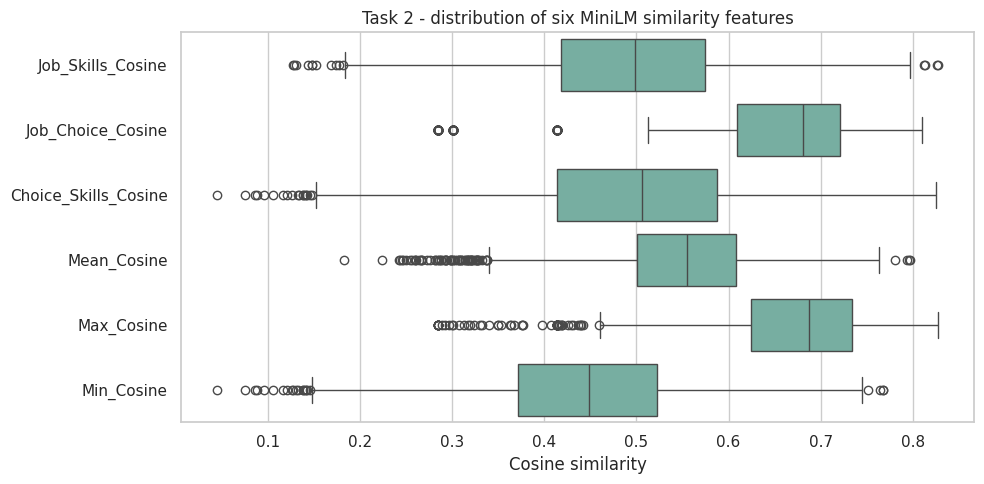

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_feature_correlation.png


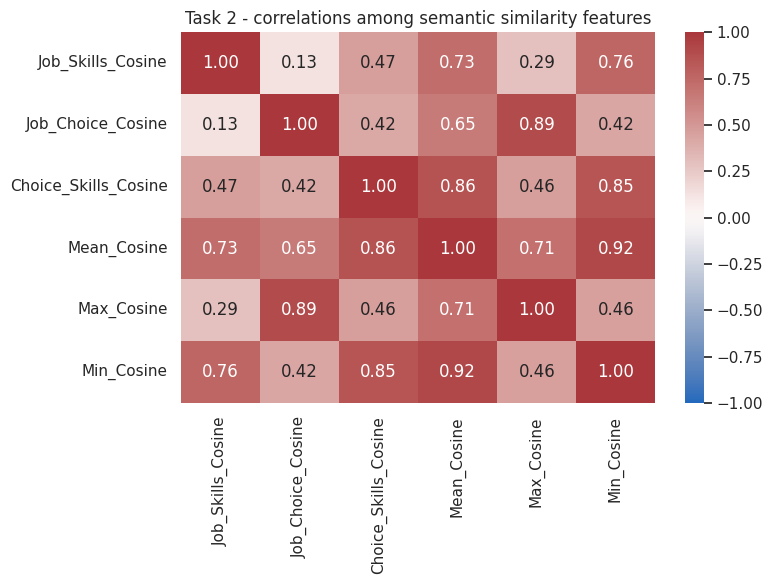

In [9]:
# Preserve the ten-feature baseline data, then append semantic similarities.
X_numeric_only = X_all.copy()
X_all = pd.concat([X_numeric_only, semantic[SEMANTIC_FEATURES]], axis=1)
if X_all.columns.tolist() != TASK2_FEATURES:
    raise AssertionError("Task 2 feature order does not match its declared schema")
if len(X_all) != len(df) or X_all.shape[1] != 16:
    raise AssertionError(f"Unexpected combined feature matrix shape {X_all.shape}")

# The same scikit-learn preprocessing handles all numeric and any optional categorical fields.
numeric_columns = X_all.select_dtypes(include="number").columns.tolist()
categorical_columns = [c for c in X_all if c not in numeric_columns]
if X_all[SEMANTIC_FEATURES].isna().any().any():
    raise ValueError("Semantic similarity values cannot be missing")

print("Task 2 feature matrix shape:", X_all.shape)
print("Numerical input columns:", numeric_columns)
print("Excluded source text:", TEXT_COLUMNS)
print("Excluded identity columns:", ID_COLUMNS)
display(X_all.head())
save_csv(X_all.assign(Original_Row_Index=X_all.index), "Task_2_all_16_features.csv")

full_feature_audit = pd.DataFrame({
    "Feature": X_all.columns,
    "Feature_Type": ["Semantic similarity" if x in SEMANTIC_FEATURES else "Original numerical"
                     for x in X_all.columns],
    "Data_Type": [str(X_all[x].dtype) for x in X_all.columns],
    "Missing_Count": [int(X_all[x].isna().sum()) for x in X_all.columns],
    "Unique_Values": [int(X_all[x].nunique(dropna=False)) for x in X_all.columns],
})
display(full_feature_audit)
save_csv(full_feature_audit, "selected_feature_audit.csv")

print("Semantic similarity descriptive statistics:")
semantic_summary = semantic.describe().T.reset_index().rename(columns={"index": "Feature"})
display(semantic_summary)
save_csv(semantic_summary, "semantic_similarity_descriptive_stats.csv")

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=semantic[SEMANTIC_FEATURES], orient="h", ax=ax, color="#6EB7A6")
ax.set(xlabel="Cosine similarity", ylabel="", title="Task 2 - distribution of six MiniLM similarity features")
plt.tight_layout()
save_plot("semantic_feature_distributions.png")
plt.show()

corr = semantic.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Task 2 - correlations among semantic similarity features")
plt.tight_layout()
save_plot("semantic_feature_correlation.png")
plt.show()

## 10. Stratified 80/20 train/test split: same records as Task 1

Hold out 20% of rows, stratified by the binary target with seed 42. The split uses target labels and row indices, not the semantic feature values, and matches the Task 1 internship notebook's row-level split on the same input dataset. We audit recurring IDs. **This is not a group-disjoint generalization experiment.**

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=RANDOM_STATE,
)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(df)

split_counts = pd.DataFrame([
    {"Split": "Train", "Negative": int((y_train == 0).sum()),
     "Positive": int((y_train == 1).sum()), "Total": len(y_train)},
    {"Split": "Test", "Negative": int((y_test == 0).sum()),
     "Positive": int((y_test == 1).sum()), "Total": len(y_test)},
])
display(split_counts)
save_csv(split_counts, "train_test_class_counts.csv")
save_csv(pd.DataFrame({"Original_Row_Index": X_train.index, "Target": y_train.to_numpy()}),
         "train_row_indices.csv")
save_csv(pd.DataFrame({"Original_Row_Index": X_test.index, "Target": y_test.to_numpy()}),
         "test_row_indices.csv")

identity_overlap = {}
for id_name in ID_COLUMNS:
    if id_name in df:
        train_ids = set(df.loc[X_train.index, id_name].dropna().astype(str))
        test_ids = set(df.loc[X_test.index, id_name].dropna().astype(str))
        identity_overlap[id_name] = len(train_ids & test_ids)
        print(f"Overlap in {id_name}: {identity_overlap[id_name]} unique IDs")
if any(identity_overlap.values()):
    print("CAUTION: Group identities overlap across train/test. "
          "These results assess new PAIRS, not necessarily new recruitment groups/applicants.")
save_json({
    "split_method": "stratified row-level train_test_split",
    "test_size": TEST_SIZE, "random_state": RANDOM_STATE,
    "train_count": len(X_train), "test_count": len(X_test),
    "identity_overlap": identity_overlap,
}, "train_test_split_audit.json")

,Split,Negative,Positive,Total
0,Train,2280,120,2400
1,Test,570,30,600


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/train_test_class_counts.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/train_row_indices.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/test_row_indices.csv
Overlap in Recruitment_ID: 75 unique IDs
Overlap in Applicant_ID: 80 unique IDs
CAUTION: Group identities overlap across train/test. These results assess new PAIRS, not necessarily new recruitment groups/applicants.
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/train_test_split_audit.json


PosixPath('/content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/train_test_split_audit.json')

## 11. Five-fold stratified cross-validation with diagram

Four folds are used for training and one for validation in every round. The fifth fold is included exactly once as validation. We do not use the test set to fit preprocessing, resample, optimize or choose thresholds.

,Fold,Training_Rows,Validation_Rows,Validation_Positives
0,1,1920,480,24
1,2,1920,480,24
2,3,1920,480,24
3,4,1920,480,24
4,5,1920,480,24


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/five_fold_cv_plan.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/five_fold_cv_diagram.png


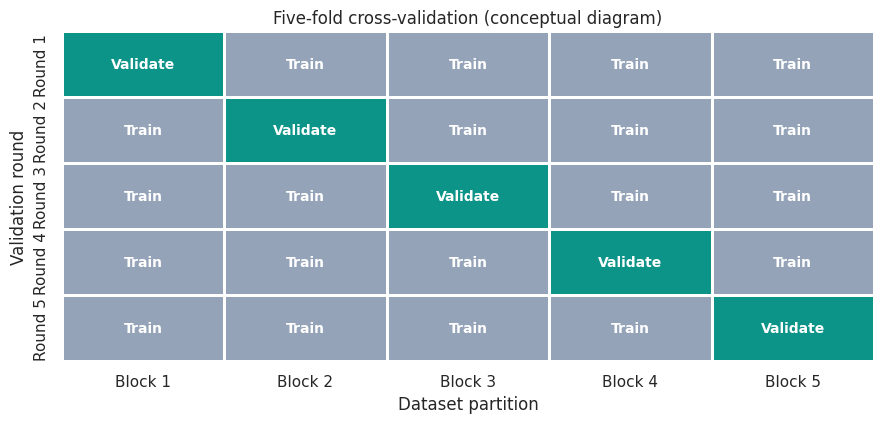

In [11]:
from matplotlib.colors import ListedColormap

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_rows = []
for fold_number, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train), 1):
    fold_rows.append({
        "Fold": fold_number,
        "Training_Rows": len(train_idx),
        "Validation_Rows": len(valid_idx),
        "Validation_Positives": int(y_train.iloc[valid_idx].sum()),
    })
fold_table = pd.DataFrame(fold_rows)
display(fold_table)
save_csv(fold_table, "five_fold_cv_plan.csv")

fold_grid = np.zeros((5, 5), dtype=int)
np.fill_diagonal(fold_grid, 1)
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.heatmap(fold_grid, cmap=ListedColormap(["#94A3B8", "#0D9488"]),
            cbar=False, linewidths=2, linecolor="white", ax=ax,
            xticklabels=[f"Block {i}" for i in range(1, 6)],
            yticklabels=[f"Round {i}" for i in range(1, 6)])
for row in range(5):
    for col in range(5):
        ax.text(col + 0.5, row + 0.5,
                "Validate" if row == col else "Train",
                ha="center", va="center", color="white", fontsize=10, fontweight="bold")
ax.set_title("Five-fold cross-validation (conceptual diagram)")
ax.set_xlabel("Dataset partition")
ax.set_ylabel("Validation round")
plt.tight_layout()
save_plot("five_fold_cv_diagram.png")
plt.show()

## 12. Leakage-safe preprocessing and oversampling pipelines

All 16 Task 2 input features are numerical. `StandardScaler` is used for Logistic Regression, while trees can work on unscaled numeric values. Imputation, optional categorical encoding and `RandomOverSampler` are inside the pipeline and are fitted only on training rows (including each training fold).

In [12]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = []
    if numeric_columns:
        transformers.append(("num", SkPipeline(numeric_steps), numeric_columns))
    if categorical_columns:
        transformers.append(("cat", SkPipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns))

    return ColumnTransformer(transformers=transformers, remainder="drop", sparse_threshold=0)


def build_pipeline(estimator, scale_numeric=False):
    return ImbPipeline(steps=[
        ("preprocess", make_preprocessor(scale_numeric=scale_numeric)),
        ("oversample", RandomOverSampler(
            sampling_strategy=OVERSAMPLING_RATIO,
            random_state=RANDOM_STATE,
        )),
        ("model", estimator),
    ])

print("Pipeline: preprocessing -> training-only RandomOverSampler -> classifier")
print("Categorical feature count:", len(categorical_columns))
print("Only Logistic Regression uses StandardScaler for numerical features.")

Pipeline: preprocessing -> training-only RandomOverSampler -> classifier
Categorical feature count: 0
Only Logistic Regression uses StandardScaler for numerical features.


## 13. Display the before-and-after oversampling counts

The baseline uses `RandomOverSampler(sampling_strategy=1.0)` to create a 1:1 class ratio **in the training partition only**. Our optimizer also considers no oversampling and 0.5 minority/majority ratio. The test partition retains its natural prevalence.

,Class,Training_Before,Training_After
0,Negative (0),2280,2280
1,Positive (1),120,2280


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/oversampling_train_counts.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/oversampling_before_after.png


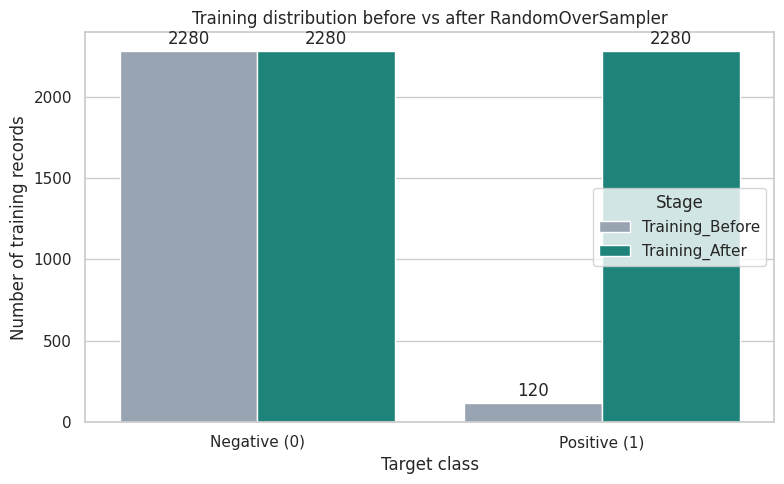

Held-out test count is unchanged: 600 | positives: 30


In [13]:
preview_sampler = RandomOverSampler(
    sampling_strategy=OVERSAMPLING_RATIO, random_state=RANDOM_STATE
)
_, y_resampled_preview = preview_sampler.fit_resample(X_train, y_train)

original_train_counts = pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0)
resampled_counts = pd.Series(y_resampled_preview).value_counts().reindex([0, 1], fill_value=0)
count_comparison = pd.DataFrame({
    "Class": ["Negative (0)", "Positive (1)"],
    "Training_Before": original_train_counts.to_numpy(),
    "Training_After": resampled_counts.to_numpy(),
})
display(count_comparison)
save_csv(count_comparison, "oversampling_train_counts.csv")

plot_counts = count_comparison.melt(id_vars="Class", var_name="Stage", value_name="Count")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(plot_counts, x="Class", y="Count", hue="Stage",
            palette=["#94A3B8", "#0D9488"], ax=ax)
ax.set_title("Training distribution before vs after RandomOverSampler")
ax.set_ylabel("Number of training records")
ax.set_xlabel("Target class")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
plt.tight_layout()
save_plot("oversampling_before_after.png")
plt.show()
print("Held-out test count is unchanged:", len(y_test),
      "| positives:", int(y_test.sum()))

## 14. Define four baseline classifiers

Logistic Regression, Random Forest, Gradient Boosting and LightGBM all see the same 16 features and the same records. The baseline uses reasonable starting hyperparameters, 1:1 oversampling and threshold 0.50.

In [14]:
MODEL_DEFINITIONS = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=2000, solver="liblinear", random_state=RANDOM_STATE
        ),
        "scale_numeric": True,
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(
            n_estimators=200, max_depth=12, min_samples_leaf=2,
            n_jobs=-1, random_state=RANDOM_STATE
        ),
        "scale_numeric": False,
    },
    "Gradient Boosting": {
        "estimator": GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.05, max_depth=3,
            random_state=RANDOM_STATE
        ),
        "scale_numeric": False,
    },
    "LightGBM": {
        "estimator": LGBMClassifier(
            objective="binary", n_estimators=200, learning_rate=0.05,
            num_leaves=15, max_depth=6, min_child_samples=20,
            reg_lambda=1.0, importance_type="gain",
            random_state=RANDOM_STATE, n_jobs=2, verbosity=-1
        ),
        "scale_numeric": False,
    },
}
print("Models configured:")
for name, spec in MODEL_DEFINITIONS.items():
    print(f"  - {name}: {spec['estimator'].__class__.__name__}")

Models configured:
  - Logistic Regression: LogisticRegression
  - Random Forest: RandomForestClassifier
  - Gradient Boosting: GradientBoostingClassifier
  - LightGBM: LGBMClassifier


## 15. Five-fold baseline cross-validation

Use the same five training-only folds for all four baseline models. Save the individual fold metrics and summary to CSV.

In [15]:
scoring = {
    "F1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "Precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "Recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "ROC_AUC": "roc_auc",
    "Balanced_Accuracy": "balanced_accuracy",
}
cv_detail_rows = []
cv_summary_rows = []
for model_name, model_info in MODEL_DEFINITIONS.items():
    print(f"\nCross-validating: {model_name} ...")
    pipeline = build_pipeline(model_info["estimator"], model_info["scale_numeric"])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=1, error_score="raise",
    )
    for fold_no in range(5):
        cv_detail_rows.append({
            "Model": model_name,
            "Fold": fold_no + 1,
            **{metric: float(scores[f"test_{metric}"][fold_no]) for metric in scoring},
        })
    summary_row = {"Model": model_name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        summary_row[f"CV_{metric}_Mean"] = float(np.mean(values))
        summary_row[f"CV_{metric}_Std"] = float(np.std(values, ddof=1))
    cv_summary_rows.append(summary_row)
    print(f"  Mean CV F1: {summary_row['CV_F1_Mean']:.4f} "
          f"± {summary_row['CV_F1_Std']:.4f}")

cv_details_df = pd.DataFrame(cv_detail_rows)
cv_summary_df = pd.DataFrame(cv_summary_rows).sort_values(
    "CV_F1_Mean", ascending=False
).reset_index(drop=True)
print("\nCross-validation summary:")
display(cv_summary_df)
save_csv(cv_details_df, "five_fold_cv_scores.csv")
save_csv(cv_summary_df, "five_fold_cv_summary.csv")


Cross-validating: Logistic Regression ...
  Mean CV F1: 0.6148 ± 0.0427

Cross-validating: Random Forest ...
  Mean CV F1: 0.7436 ± 0.0682

Cross-validating: Gradient Boosting ...
  Mean CV F1: 0.7071 ± 0.0549

Cross-validating: LightGBM ...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  Mean CV F1: 0.7526 ± 0.0911

Cross-validation summary:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,CV_F1_Mean,CV_F1_Std,CV_Precision_Mean,CV_Precision_Std,CV_Recall_Mean,CV_Recall_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_Balanced_Accuracy_Mean,CV_Balanced_Accuracy_Std
0,LightGBM,0.752622,0.091083,0.741004,0.129545,0.775000,0.095924,0.986202,0.006292,0.879825,0.048206
1,Random Forest,0.743625,0.068246,0.741118,0.111997,0.758333,0.095015,0.984942,0.005331,0.871711,0.046313
2,Gradient Boosting,0.707127,0.054931,0.623841,0.083052,0.825000,0.054327,0.983562,0.005777,0.898904,0.026627
3,Logistic Regression,0.614823,0.042711,0.457058,0.037706,0.941667,0.063191,0.986294,0.007354,0.941228,0.032011


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/five_fold_cv_scores.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/five_fold_cv_summary.csv


PosixPath('/content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/five_fold_cv_summary.csv')

## 16. Optimization - hyperparameters, balancing strategy and threshold

For each classifier, compare 8 randomized parameter candidates x 3 class-balancing methods x 5 folds (120 fits per model). Rank by out-of-fold F1 after choosing the best probability threshold using training out-of-fold predictions. The held-out test labels are never used for optimization.

**F1 definition:** \(F_1 = 2PR/(P+R)\), where \(P=TP/(TP+FP)\) and \(R=TP/(TP+FN)\). A score near 1 means better balance of positive-class precision and recall.

In [16]:
SEARCH_SPACES = {
    "Logistic Regression": {
        "C": loguniform(0.03, 30.0),
        "penalty": ["l1", "l2"],
    },
    "Random Forest": {
        "n_estimators": randint(120, 320),
        "max_depth": [5, 8, 12, 16, None],
        "min_samples_leaf": randint(1, 8),
        "min_samples_split": randint(2, 14),
        "max_features": ["sqrt", 0.7, 1.0],
        "max_samples": [0.75, 0.9, None],
    },
    "Gradient Boosting": {
        "n_estimators": randint(80, 300),
        "learning_rate": loguniform(0.02, 0.2),
        "max_depth": [2, 3, 4],
        "min_samples_leaf": randint(2, 20),
        "subsample": uniform(0.72, 0.28),
        "max_features": [0.7, 0.9, None],
    },
    "LightGBM": {
        "n_estimators": randint(100, 400),
        "learning_rate": loguniform(0.02, 0.14),
        "num_leaves": randint(7, 32),
        "max_depth": [3, 4, 5, 6, -1],
        "min_child_samples": randint(8, 45),
        "reg_alpha": loguniform(0.001, 3.0),
        "reg_lambda": loguniform(0.02, 12.0),
        "colsample_bytree": uniform(0.7, 0.3),
    },
}

def optimized_pipeline(model_name, params, strategy):
    """Fresh pipeline; all preprocessing and sampling happen within training data."""
    if strategy not in BALANCE_STRATEGIES:
        raise ValueError(f"Invalid imbalance strategy: {strategy}")
    spec = MODEL_DEFINITIONS[model_name]
    model = clone(spec["estimator"]).set_params(**params)
    ratio = BALANCE_STRATEGIES[strategy]
    sampler = ("passthrough" if ratio is None else
               RandomOverSampler(sampling_strategy=ratio, random_state=RANDOM_STATE))
    return ImbPipeline([
        ("preprocess", make_preprocessor(scale_numeric=spec["scale_numeric"])),
        ("oversample", sampler),
        ("model", model),
    ])

folds = list(cv.split(X_train, y_train))
assert len(folds) == 5

def find_best_oof_threshold(labels, probabilities):
    scores = np.array([
        f1_score(labels, probabilities >= t, zero_division=0)
        for t in THRESHOLDS
    ])
    winners = np.flatnonzero(np.isclose(scores, scores.max()))
    best_idx = winners[np.argmin(np.abs(THRESHOLDS[winners] - 0.50))]
    return float(THRESHOLDS[best_idx]), float(scores[best_idx])

print("Optimization search ready:", N_SEARCH_PER_MODEL, "parameter sets x",
      len(BALANCE_STRATEGIES), "balancing options x", len(folds), "folds / model")

Optimization search ready: 8 parameter sets x 3 balancing options x 5 folds / model


In [17]:
# Searches only X_train/y_train. No held-out test values are accessed here.
from sklearn.metrics import average_precision_score

optimization_rows = []
selected_rows = []
selected_config = {}
selected_oof = {}

for model_number, (model_name, spec) in enumerate(MODEL_DEFINITIONS.items(), 1):
    print("\n" + "=" * 72)
    print(f"OPTIMIZING {model_name} ({model_number}/{len(MODEL_DEFINITIONS)})")
    print("=" * 72)
    candidates = list(ParameterSampler(
        SEARCH_SPACES[model_name], n_iter=N_SEARCH_PER_MODEL, random_state=RANDOM_STATE
    ))
    model_results = []
    safe_name = model_name.replace(" ", "_")
    best_oof = None
    best_key = None

    for candidate_no, params in enumerate(candidates, start=1):
        for strategy in BALANCE_STRATEGIES:
            probabilities = np.full(len(X_train), np.nan, dtype=float)
            for fit_idx, val_idx in folds:
                p = optimized_pipeline(model_name, params, strategy)
                p.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
                classes = list(p.named_steps["model"].classes_)
                probabilities[val_idx] = p.predict_proba(X_train.iloc[val_idx])[:, classes.index(1)]
            if not np.isfinite(probabilities).all():
                raise RuntimeError(f"Missing out-of-fold predictions for {model_name}")
            threshold, pooled_f1 = find_best_oof_threshold(y_train.to_numpy(), probabilities)
            fold_f1 = [f1_score(y_train.iloc[val], probabilities[val] >= threshold,
                                zero_division=0) for _, val in folds]
            pr_auc = float(average_precision_score(y_train, probabilities))
            row = {
                "Model": model_name,
                "Candidate": candidate_no,
                "Strategy": strategy,
                "OOF_Selection_F1": pooled_f1,
                "OOF_Precision": float(precision_score(y_train, probabilities >= threshold, zero_division=0)),
                "OOF_Recall": float(recall_score(y_train, probabilities >= threshold, zero_division=0)),
                "OOF_PR_AUC": pr_auc,
                "Fold_F1_Std": float(np.std(fold_f1, ddof=1)),
                "Threshold": threshold,
                "Parameters": json.dumps(params, sort_keys=True, default=lambda o: o.item() if isinstance(o, np.generic) else str(o)),
            }
            model_results.append(row)
            key = (pooled_f1, pr_auc, -float(np.std(fold_f1, ddof=1)))
            if best_key is None or key > best_key:
                best_key = key
                best_oof = probabilities.copy()
        # Checkpoint search results after each parameter set; survives a Colab disconnect.
        checkpoint = pd.DataFrame(model_results)
        checkpoint.to_csv(OUTPUT_DIR / f"{safe_name}_optimization_search.csv", index=False)
        print(f"  parameter set {candidate_no}/{N_SEARCH_PER_MODEL} complete; "
              f"best OOF selection F1 = {best_key[0]:.4f}", flush=True)

    ranked = pd.DataFrame(model_results).sort_values(
        ["OOF_Selection_F1", "OOF_PR_AUC", "Fold_F1_Std"],
        ascending=[False, False, True]
    ).reset_index(drop=True)
    best = ranked.iloc[0].to_dict()
    selected_config[model_name] = {
        "strategy": best["Strategy"],
        "params": json.loads(best["Parameters"]),
        "threshold": float(best["Threshold"]),
        "oof_selection_f1": float(best["OOF_Selection_F1"]),
    }
    selected_oof[model_name] = best_oof
    selected_rows.append({key: value for key, value in best.items() if key != "Parameters"})
    optimization_rows.extend(model_results)
    save_json(selected_config[model_name], f"{safe_name}_selected_optimization.json")
    save_csv(pd.DataFrame({
        "Original_Row_Index": X_train.index,
        "Actual": y_train.to_numpy(),
        "OOF_Positive_Probability": best_oof,
        "OOF_Prediction": (best_oof >= float(best["Threshold"])).astype(int),
    }), f"{safe_name}_optimized_train_oof_predictions.csv")
    print(f"Selected: {best['Strategy']}, threshold={best['Threshold']:.2f}, "
          f"OOF selection F1={best['OOF_Selection_F1']:.4f}")

optimization_df = pd.DataFrame(optimization_rows)
selected_df = pd.DataFrame(selected_rows).sort_values("OOF_Selection_F1", ascending=False)
save_csv(optimization_df, "all_optimization_trials.csv")
save_csv(selected_df, "selected_optimized_cv_configurations.csv")
print("\nBEST TRAINING-ONLY CONFIGURATIONS:")
display(selected_df[["Model", "Strategy", "Threshold", "OOF_Selection_F1", "OOF_PR_AUC", "Fold_F1_Std"]])
print("NOTE: OOF selection F1 is optimistic because parameters and threshold were selected on it.")


OPTIMIZING Logistic Regression (1/4)
  parameter set 1/8 complete; best OOF selection F1 = 0.7838
  parameter set 2/8 complete; best OOF selection F1 = 0.7838
  parameter set 3/8 complete; best OOF selection F1 = 0.7838
  parameter set 4/8 complete; best OOF selection F1 = 0.7838
  parameter set 5/8 complete; best OOF selection F1 = 0.7838
  parameter set 6/8 complete; best OOF selection F1 = 0.7879
  parameter set 7/8 complete; best OOF selection F1 = 0.7879
  parameter set 8/8 complete; best OOF selection F1 = 0.7879
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Logistic_Regression_selected_optimization.json
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Logistic_Regression_optimized_train_oof_predictions.csv
Selected: oversample_0.5, threshold=0.88, OOF selection F1=0.7879

OPTIMIZING Random Forest (2/4)
  parameter set 1/8 complete; best OOF selection F1 = 0.7822
  parameter set 2/8 complete; best OOF s

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  parameter set 1/8 complete; best OOF selection F1 = 0.7692


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  parameter set 2/8 complete; best OOF selection F1 = 0.7731


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

... (9 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  parameter set 8/8 complete; best OOF selection F1 = 0.7897
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/LightGBM_selected_optimization.json
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/LightGBM_optimized_train_oof_predictions.csv
Selected: none, threshold=0.46, OOF selection F1=0.7897
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/all_optimization_trials.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/selected_optimized_cv_configurations.csv

BEST TRAINING-ONLY CONFIGURATIONS:


,Model,Strategy,Threshold,OOF_Selection_F1,OOF_PR_AUC,Fold_F1_Std
1,Random Forest,none,0.54,0.791111,0.826322,0.053376
3,LightGBM,none,0.46,0.789700,0.802306,0.069195
0,Logistic Regression,oversample_0.5,0.88,0.787879,0.818124,0.060394
2,Gradient Boosting,none,0.60,0.786026,0.812788,0.056324


NOTE: OOF selection F1 is optimistic because parameters and threshold were selected on it.


## 17. Review optimized settings from training folds

Compare baseline fold scores with optimized out-of-fold selection scores. These are not directly equivalent estimators because the optimization searches thresholds and models using the same OOF predictions, so its selection F1 is optimistic.

,Model,Baseline_Fold_Mean_F1,CV_F1_Std,Optimized_Selection_OOF_F1,Fold_F1_Std,Strategy,Threshold
0,LightGBM,0.752622,0.091083,0.789700,0.069195,none,0.46
1,Random Forest,0.743625,0.068246,0.791111,0.053376,none,0.54
2,Gradient Boosting,0.707127,0.054931,0.786026,0.056324,none,0.60
3,Logistic Regression,0.614823,0.042711,0.787879,0.060394,oversample_0.5,0.88


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/baseline_vs_optimized_training_cv.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/training_cv_baseline_vs_optimized.png


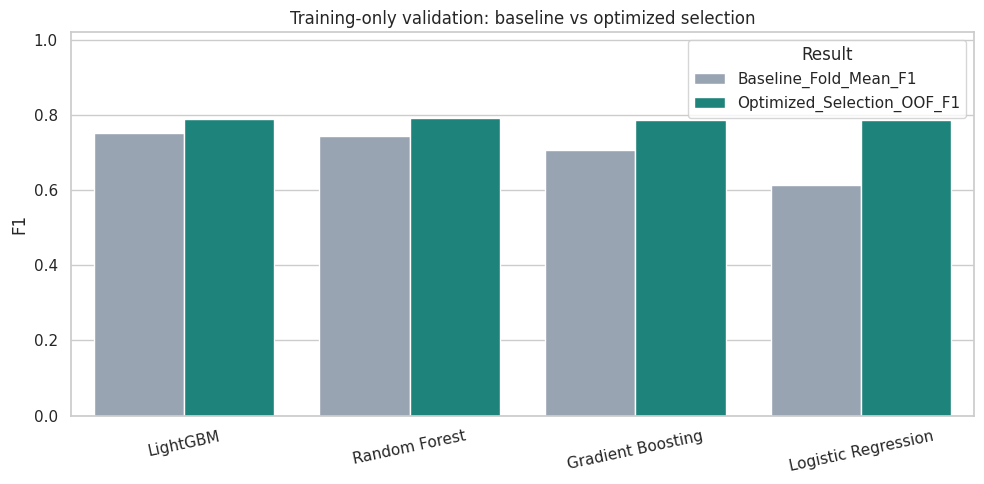

In [18]:
baseline_cv_for_compare = cv_summary_df[["Model", "CV_F1_Mean", "CV_F1_Std"]].copy()
optimized_cv_for_compare = selected_df[["Model", "OOF_Selection_F1", "Fold_F1_Std", "Strategy", "Threshold"]].copy()
cv_comparison = baseline_cv_for_compare.merge(optimized_cv_for_compare, on="Model", validate="one_to_one")
cv_comparison = cv_comparison.rename(columns={"CV_F1_Mean": "Baseline_Fold_Mean_F1", "OOF_Selection_F1": "Optimized_Selection_OOF_F1"})
display(cv_comparison)
save_csv(cv_comparison, "baseline_vs_optimized_training_cv.csv")

fig, ax = plt.subplots(figsize=(10, 5))
plotting = cv_comparison.melt(id_vars="Model", value_vars=["Baseline_Fold_Mean_F1", "Optimized_Selection_OOF_F1"], var_name="Result", value_name="F1")
sns.barplot(data=plotting, x="Model", y="F1", hue="Result", palette=["#94A3B8", "#0D9488"], ax=ax)
ax.set(ylim=(0, 1.02), title="Training-only validation: baseline vs optimized selection", xlabel="", ylabel="F1")
ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
save_plot("training_cv_baseline_vs_optimized.png")
plt.show()

## 18. Train final models and evaluate the common held-out test set

Refit each baseline and selected optimized pipeline on all training rows. Evaluate each on the **same unchanged test rows** and save precision, recall, F1, balanced accuracy, ROC-AUC, classification report, confusion-matrix heatmap, predicted probabilities, ROC curve and trained model pipeline. The positive class is label 1.


FITTING + TESTING: Baseline Logistic Regression
TEST metrics: {'Stage': 'Baseline', 'Model': 'Logistic Regression', 'Precision': 0.5088, 'Recall': 0.9667, 'F1_Score': 0.6667, 'ROC_AUC': 0.9919, 'Balanced_Accuracy': 0.9588, 'Threshold': 0.5, 'Imbalance_Strategy': 'oversample_1.0'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       1.00      0.95      0.97       570
Positive (1)       0.51      0.97      0.67        30

    accuracy                           0.95       600
   macro avg       0.75      0.96      0.82       600
weighted avg       0.97      0.95      0.96       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Logistic_Regression_classification_report.txt
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Logistic_Regression_classification_report.csv
Confusion matrix:
                      Predicted Negative (0)  Predicted Positive (1

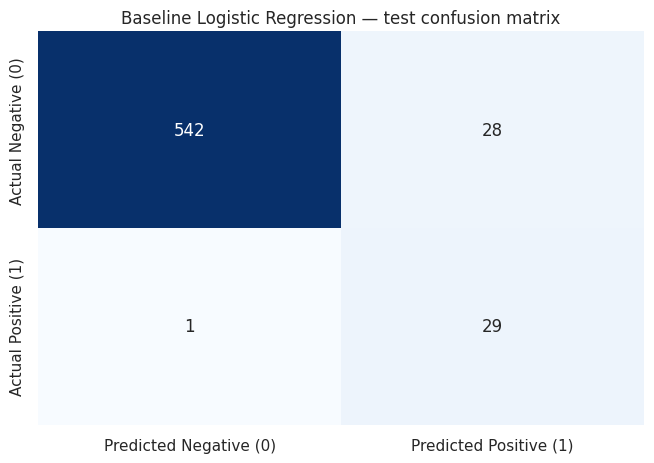

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Logistic_Regression_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Logistic_Regression_roc_curve.png


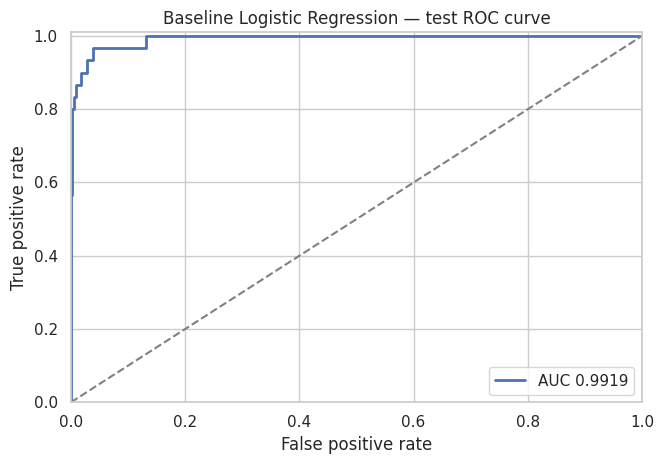

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Logistic_Regression_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Logistic_Regression_trained_pipeline.joblib

FITTING + TESTING: Optimized Logistic Regression
TEST metrics: {'Stage': 'Optimized', 'Model': 'Logistic Regression', 'Precision': 0.8621, 'Recall': 0.8333, 'F1_Score': 0.8475, 'ROC_AUC': 0.9932, 'Balanced_Accuracy': 0.9132, 'Threshold': 0.88, 'Imbalance_Strategy': 'oversample_0.5'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      0.99      0.99       570
Positive (1)       0.86      0.83      0.85        30

    accuracy                           0.98       600
   macro avg       0.93      0.91      0.92       600
weighted avg       0.98      0.98      0.98       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Opt

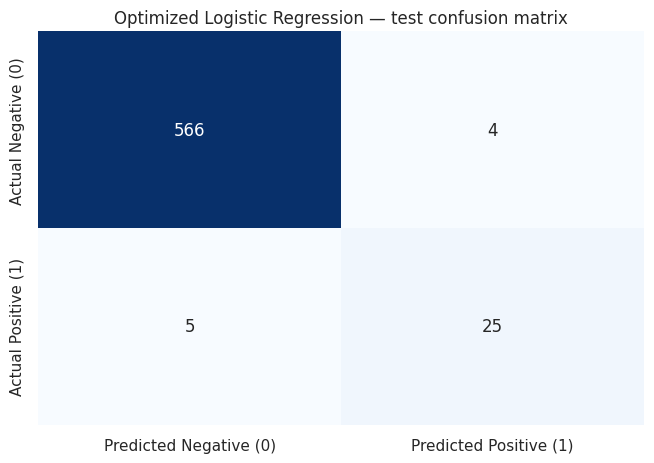

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Logistic_Regression_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Logistic_Regression_roc_curve.png


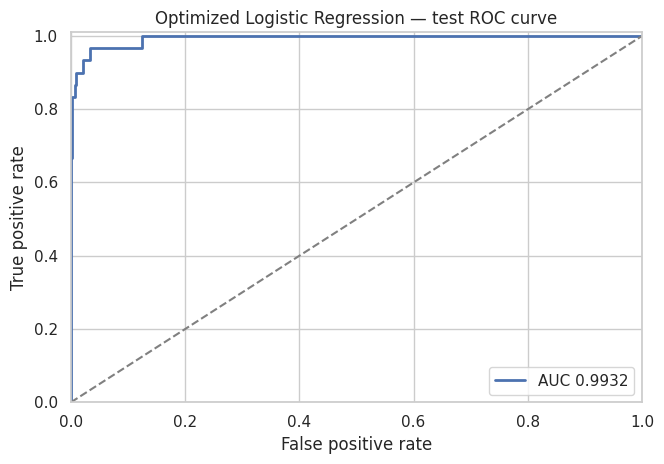

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Logistic_Regression_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Logistic_Regression_trained_pipeline.joblib

FITTING + TESTING: Baseline Random Forest
TEST metrics: {'Stage': 'Baseline', 'Model': 'Random Forest', 'Precision': 0.7222, 'Recall': 0.8667, 'F1_Score': 0.7879, 'ROC_AUC': 0.9891, 'Balanced_Accuracy': 0.9246, 'Threshold': 0.5, 'Imbalance_Strategy': 'oversample_1.0'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      0.98      0.99       570
Positive (1)       0.72      0.87      0.79        30

    accuracy                           0.98       600
   macro avg       0.86      0.92      0.89       600
weighted avg       0.98      0.98      0.98       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Random_

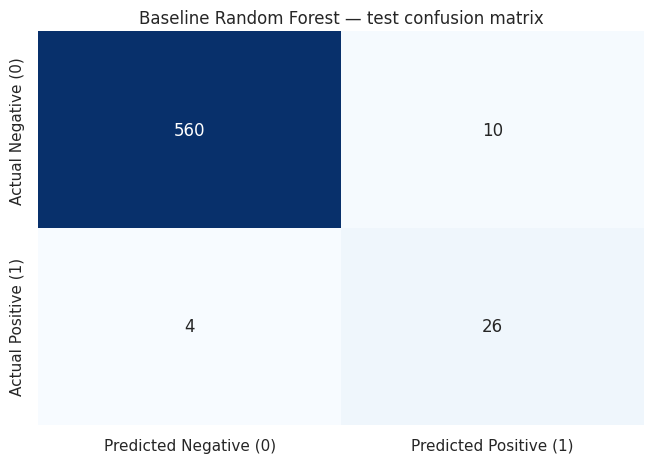

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Random_Forest_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Random_Forest_roc_curve.png


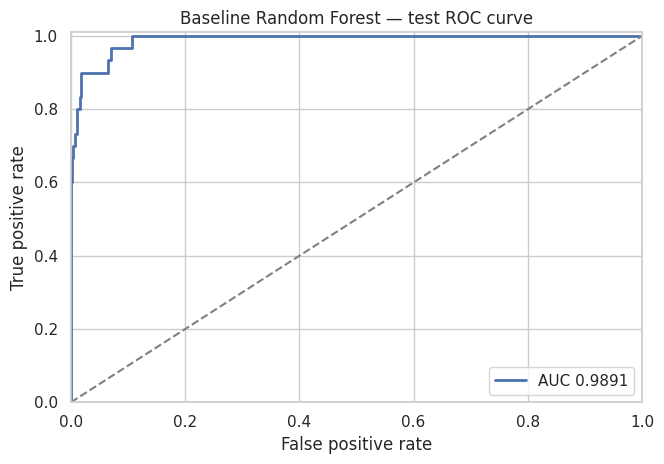

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Random_Forest_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Random_Forest_trained_pipeline.joblib

FITTING + TESTING: Optimized Random Forest
TEST metrics: {'Stage': 'Optimized', 'Model': 'Random Forest', 'Precision': 0.9259, 'Recall': 0.8333, 'F1_Score': 0.8772, 'ROC_AUC': 0.9939, 'Balanced_Accuracy': 0.9149, 'Threshold': 0.54, 'Imbalance_Strategy': 'none'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      1.00      0.99       570
Positive (1)       0.93      0.83      0.88        30

    accuracy                           0.99       600
   macro avg       0.96      0.91      0.94       600
weighted avg       0.99      0.99      0.99       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_classificatio

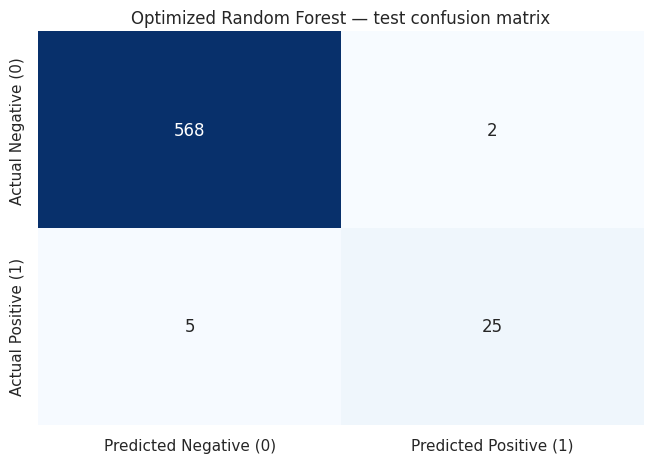

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_roc_curve.png


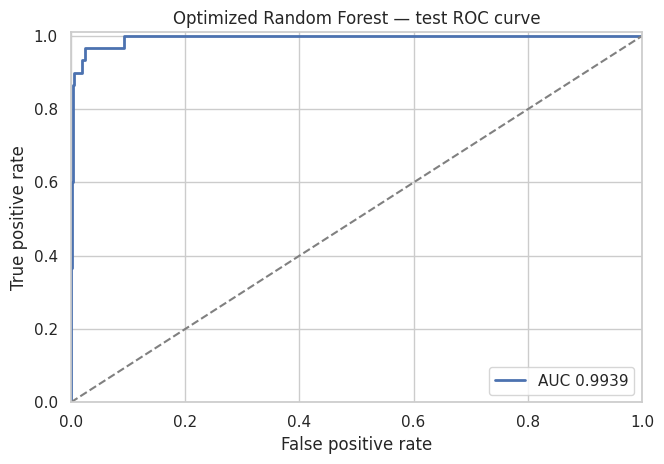

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_trained_pipeline.joblib

FITTING + TESTING: Baseline Gradient Boosting
TEST metrics: {'Stage': 'Baseline', 'Model': 'Gradient Boosting', 'Precision': 0.6429, 'Recall': 0.9, 'F1_Score': 0.75, 'ROC_AUC': 0.9885, 'Balanced_Accuracy': 0.9368, 'Threshold': 0.5, 'Imbalance_Strategy': 'oversample_1.0'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      0.97      0.98       570
Positive (1)       0.64      0.90      0.75        30

    accuracy                           0.97       600
   macro avg       0.82      0.94      0.87       600
weighted avg       0.98      0.97      0.97       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Gradient_Boostin

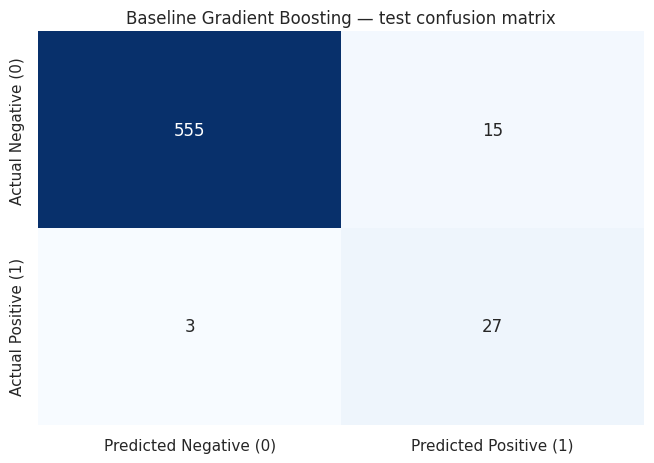

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Gradient_Boosting_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Gradient_Boosting_roc_curve.png


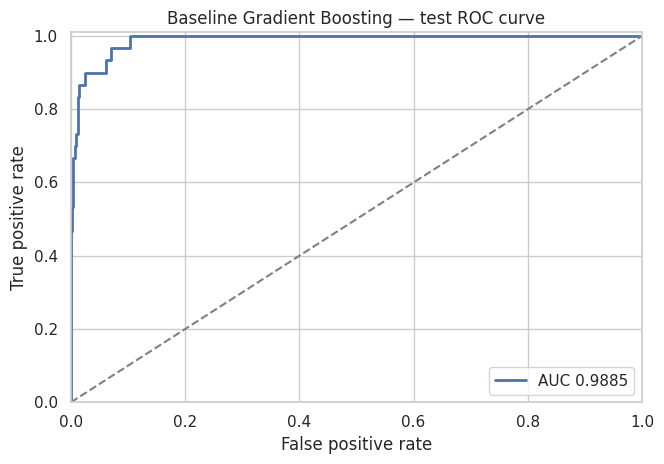

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Gradient_Boosting_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_Gradient_Boosting_trained_pipeline.joblib

FITTING + TESTING: Optimized Gradient Boosting
TEST metrics: {'Stage': 'Optimized', 'Model': 'Gradient Boosting', 'Precision': 0.8929, 'Recall': 0.8333, 'F1_Score': 0.8621, 'ROC_AUC': 0.9935, 'Balanced_Accuracy': 0.914, 'Threshold': 0.6, 'Imbalance_Strategy': 'none'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      0.99      0.99       570
Positive (1)       0.89      0.83      0.86        30

    accuracy                           0.99       600
   macro avg       0.94      0.91      0.93       600
weighted avg       0.99      0.99      0.99       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boos

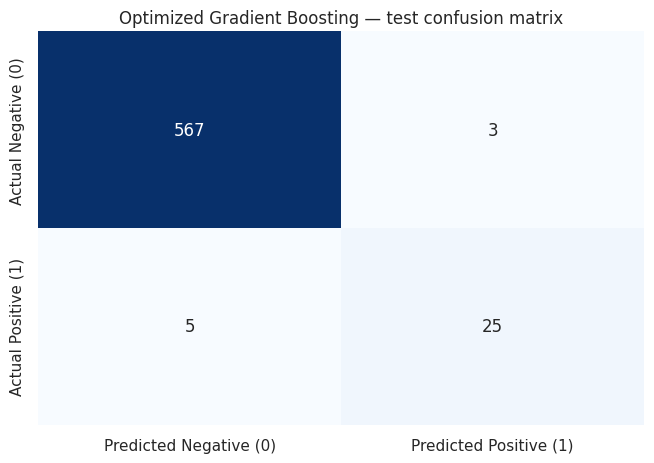

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boosting_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boosting_roc_curve.png


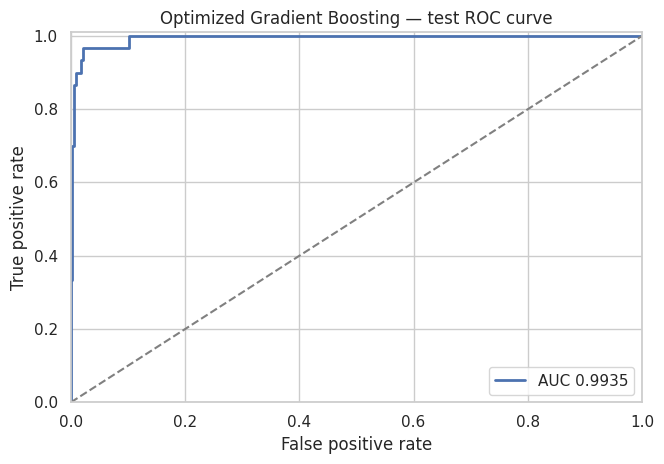

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boosting_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boosting_trained_pipeline.joblib

FITTING + TESTING: Baseline LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


TEST metrics: {'Stage': 'Baseline', 'Model': 'LightGBM', 'Precision': 0.7429, 'Recall': 0.8667, 'F1_Score': 0.8, 'ROC_AUC': 0.9915, 'Balanced_Accuracy': 0.9254, 'Threshold': 0.5, 'Imbalance_Strategy': 'oversample_1.0'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      0.98      0.99       570
Positive (1)       0.74      0.87      0.80        30

    accuracy                           0.98       600
   macro avg       0.87      0.93      0.89       600
weighted avg       0.98      0.98      0.98       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_LightGBM_classification_report.txt
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_LightGBM_classification_report.csv
Confusion matrix:
                      Predicted Negative (0)  Predicted Positive (1)
Actual Negative (0)                     561                       9
Actual Positive

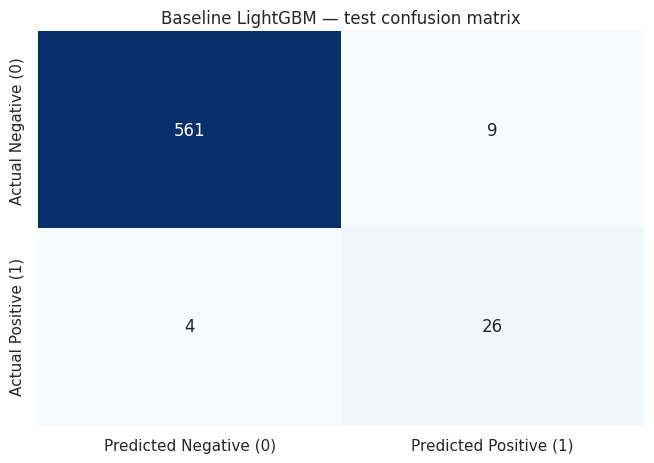

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_LightGBM_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_LightGBM_roc_curve.png


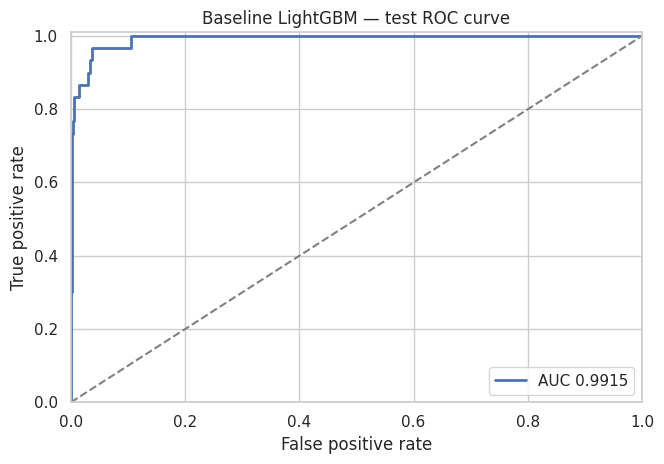

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_LightGBM_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Baseline_LightGBM_trained_pipeline.joblib

FITTING + TESTING: Optimized LightGBM
TEST metrics: {'Stage': 'Optimized', 'Model': 'LightGBM', 'Precision': 0.8966, 'Recall': 0.8667, 'F1_Score': 0.8814, 'ROC_AUC': 0.9935, 'Balanced_Accuracy': 0.9307, 'Threshold': 0.46, 'Imbalance_Strategy': 'none'}
Classification report:
               precision    recall  f1-score   support

Negative (0)       0.99      0.99      0.99       570
Positive (1)       0.90      0.87      0.88        30

    accuracy                           0.99       600
   macro avg       0.94      0.93      0.94       600
weighted avg       0.99      0.99      0.99       600

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_classification_report.txt


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_classification_report.csv
Confusion matrix:
                      Predicted Negative (0)  Predicted Positive (1)
Actual Negative (0)                     567                       3
Actual Positive (1)                       4                      26
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_confusion_matrix.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_confusion_matrix.png


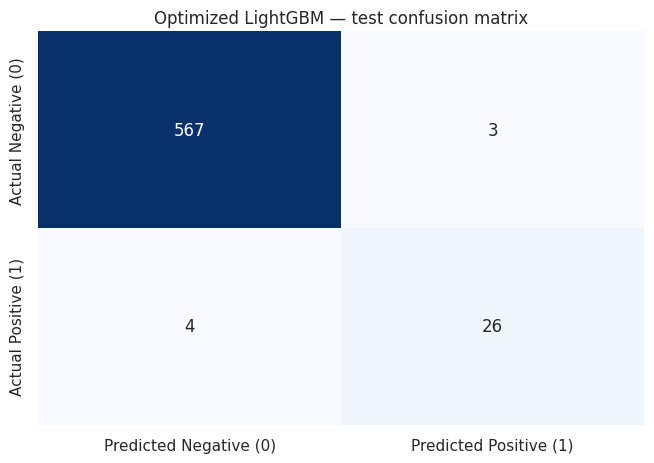

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_roc_curve.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_roc_curve.png


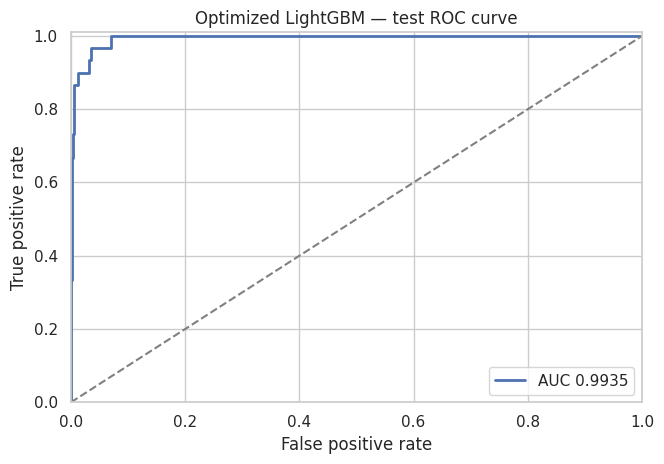

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_test_predictions.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_trained_pipeline.joblib
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/all_baseline_and_optimized_test_metrics.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/all_baseline_and_optimized_test_predictions.csv

Finished evaluating baseline and optimized versions of all four classifiers.


In [19]:
trained_pipelines = {}         # keyed by ("Baseline"/"Optimized", model name)
all_test_rows = []
roc_data = {}                 # keyed by stage and model
all_test_predictions = []

for model_name, spec in MODEL_DEFINITIONS.items():
    for stage in ["Baseline", "Optimized"]:
        safe = model_name.replace(" ", "_")
        prefix = f"{stage}_{safe}"
        print("\n" + "=" * 70)
        print(f"FITTING + TESTING: {stage} {model_name}")
        print("=" * 70)
        if stage == "Baseline":
            pipeline = build_pipeline(clone(spec["estimator"]), spec["scale_numeric"])
            threshold = 0.50
            imbalance_method = "oversample_1.0"
        else:
            cfg = selected_config[model_name]
            pipeline = optimized_pipeline(model_name, cfg["params"], cfg["strategy"])
            threshold = float(cfg["threshold"])
            imbalance_method = cfg["strategy"]

        pipeline.fit(X_train, y_train)
        trained_pipelines[(stage, model_name)] = pipeline
        model_classes = list(pipeline.named_steps["model"].classes_)
        positive_column = model_classes.index(1)
        probability = pipeline.predict_proba(X_test)[:, positive_column]
        predicted = (probability >= threshold).astype(int)

        row = {
            "Stage": stage,
            "Model": model_name,
            "Precision": float(precision_score(y_test, predicted, zero_division=0)),
            "Recall": float(recall_score(y_test, predicted, zero_division=0)),
            "F1_Score": float(f1_score(y_test, predicted, zero_division=0)),
            "ROC_AUC": float(roc_auc_score(y_test, probability)),
            "Balanced_Accuracy": float(balanced_accuracy_score(y_test, predicted)),
            "Threshold": threshold,
            "Imbalance_Strategy": imbalance_method,
        }
        all_test_rows.append(row)
        print("TEST metrics:", {key: (round(value, 4) if isinstance(value, float) else value)
                                for key, value in row.items()})
        report = classification_report(
            y_test, predicted, labels=[0, 1],
            target_names=["Negative (0)", "Positive (1)"], zero_division=0
        )
        print("Classification report:\n", report)
        report_path = OUTPUT_DIR / f"{prefix}_classification_report.txt"
        report_path.write_text(report, encoding="utf-8")
        print("SAVED:", report_path)
        save_csv(pd.DataFrame(classification_report(y_test, predicted,
                      output_dict=True, zero_division=0)).T.reset_index().rename(
                      columns={"index": "Class"}), f"{prefix}_classification_report.csv")

        matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
        matrix_frame = pd.DataFrame(matrix,
            index=["Actual Negative (0)", "Actual Positive (1)"],
            columns=["Predicted Negative (0)", "Predicted Positive (1)"])
        print("Confusion matrix:\n", matrix_frame.to_string())
        save_csv(matrix_frame.reset_index().rename(columns={"index": "Actual_Class"}),
                 f"{prefix}_confusion_matrix.csv")
        fig, ax = plt.subplots(figsize=(6.7, 4.8))
        sns.heatmap(matrix_frame, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{stage} {model_name} — test confusion matrix")
        plt.tight_layout()
        save_plot(f"{prefix}_confusion_matrix.png")
        plt.show()

        fpr, tpr, roc_thresholds = roc_curve(y_test, probability, pos_label=1)
        roc_frame = pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds})
        roc_data[(stage, model_name)] = roc_frame
        save_csv(roc_frame, f"{prefix}_roc_curve.csv")
        fig, ax = plt.subplots(figsize=(6.8, 4.8))
        ax.plot(fpr, tpr, lw=2, label=f"AUC {row['ROC_AUC']:.4f}")
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
        ax.set(xlabel="False positive rate", ylabel="True positive rate",
               title=f"{stage} {model_name} — test ROC curve", xlim=(0, 1), ylim=(0, 1.01))
        ax.legend(loc="lower right")
        plt.tight_layout()
        save_plot(f"{prefix}_roc_curve.png")
        plt.show()

        predictions = pd.DataFrame({
            "Original_Row_Index": X_test.index,
            "Stage": stage,
            "Model": model_name,
            "Actual_Positive_Class": y_test.to_numpy(),
            "Predicted_Positive_Class": predicted,
            "Positive_Class_Probability": probability,
            "Classification_Threshold": threshold,
        })
        for id_col in ID_COLUMNS:
            if id_col in df.columns:
                predictions[id_col] = df.loc[X_test.index, id_col].to_numpy()
        all_test_predictions.append(predictions)
        save_csv(predictions, f"{prefix}_test_predictions.csv")

        model_path = OUTPUT_DIR / f"{prefix}_trained_pipeline.joblib"
        joblib.dump(pipeline, model_path)
        print("SAVED:", model_path)

all_test_df = pd.DataFrame(all_test_rows)
all_test_prediction_df = pd.concat(all_test_predictions, ignore_index=True)
save_csv(all_test_df.sort_values(["Stage", "F1_Score"], ascending=[True, False]),
         "all_baseline_and_optimized_test_metrics.csv")
save_csv(all_test_prediction_df, "all_baseline_and_optimized_test_predictions.csv")
print("\nFinished evaluating baseline and optimized versions of all four classifiers.")

## 19. Plot the four optimized test ROC curves on one chart

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/optimized_combined_roc_curves.png


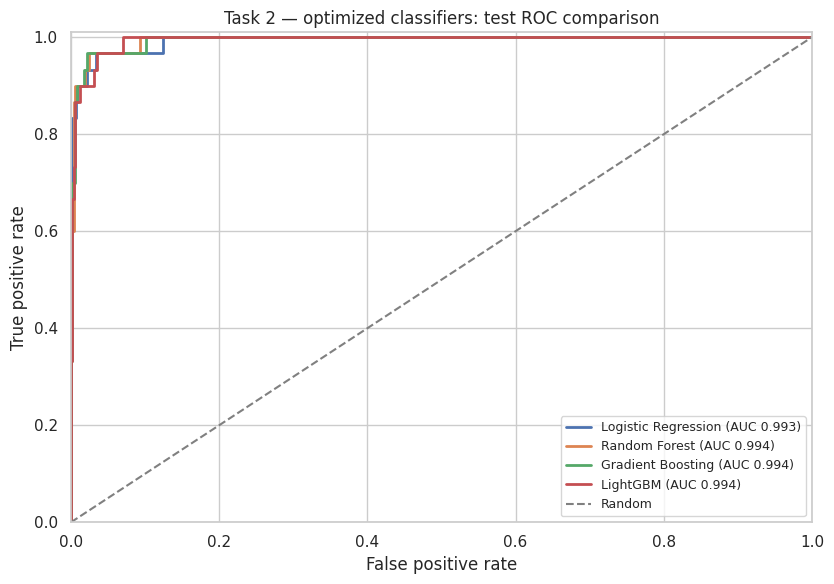

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 6))
for model_name in MODEL_DEFINITIONS:
    curve = roc_data[("Optimized", model_name)]
    auc = float(all_test_df.query("Stage == 'Optimized' and Model == @model_name")["ROC_AUC"].iloc[0])
    ax.plot(curve["FPR"], curve["TPR"], linewidth=2,
            label=f"{model_name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title="Task 2 — optimized classifiers: test ROC comparison",
       xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_plot("optimized_combined_roc_curves.png")
plt.show()

## 20. Compare four models: baseline versus optimized test results

In [21]:
cols = ["Stage", "Model", "Precision", "Recall", "F1_Score", "ROC_AUC", "Balanced_Accuracy", "Threshold", "Imbalance_Strategy"]
comparison_df = all_test_df[cols].sort_values(["Stage", "F1_Score"], ascending=[True, False]).reset_index(drop=True)
print("ALL 8 FINAL TEST EVALUATIONS:")
display(comparison_df.style.format({
    "Precision": "{:.4f}", "Recall": "{:.4f}", "F1_Score": "{:.4f}",
    "ROC_AUC": "{:.4f}", "Balanced_Accuracy": "{:.4f}", "Threshold": "{:.2f}",
}))
save_csv(comparison_df, "final_model_comparison.csv")

baseline_metrics = comparison_df.query("Stage == 'Baseline'").drop(columns=["Stage", "Threshold", "Imbalance_Strategy"]).set_index("Model")
optimized_metrics = comparison_df.query("Stage == 'Optimized'").drop(columns=["Stage", "Threshold", "Imbalance_Strategy"]).set_index("Model")
paired = baseline_metrics.join(optimized_metrics, lsuffix="_Baseline", rsuffix="_Optimized").reset_index()
paired["Test_F1_Change_Optimized_minus_Baseline"] = paired["F1_Score_Optimized"] - paired["F1_Score_Baseline"]
print("\nPAIRED F1 COMPARISON:")
display(paired[["Model", "F1_Score_Baseline", "F1_Score_Optimized", "Test_F1_Change_Optimized_minus_Baseline"]])
save_csv(paired, "paired_baseline_vs_optimized_comparison.csv")

cv_leader = selected_df.sort_values("OOF_Selection_F1", ascending=False).iloc[0]
print(f"CV-selected optimized model: {cv_leader['Model']} "
      f"(OOF selection F1 {cv_leader['OOF_Selection_F1']:.4f})")
observed = comparison_df.query("Stage == 'Optimized'").sort_values("F1_Score", ascending=False).iloc[0]
print(f"Highest observed optimized TEST F1: {observed['Model']} ({observed['F1_Score']:.4f}); "
      "this is exploratory, not a basis for further test-set tuning.")

ALL 8 FINAL TEST EVALUATIONS:


,Stage,Model,Precision,Recall,F1_Score,ROC_AUC,Balanced_Accuracy,Threshold,Imbalance_Strategy
0,Baseline,LightGBM,0.7429,0.8667,0.8000,0.9915,0.9254,0.50,oversample_1.0
1,Baseline,Random Forest,0.7222,0.8667,0.7879,0.9891,0.9246,0.50,oversample_1.0
2,Baseline,Gradient Boosting,0.6429,0.9000,0.7500,0.9885,0.9368,0.50,oversample_1.0
3,Baseline,Logistic Regression,0.5088,0.9667,0.6667,0.9919,0.9588,0.50,oversample_1.0
4,Optimized,LightGBM,0.8966,0.8667,0.8814,0.9935,0.9307,0.46,none
5,Optimized,Random Forest,0.9259,0.8333,0.8772,0.9939,0.9149,0.54,none
6,Optimized,Gradient Boosting,0.8929,0.8333,0.8621,0.9935,0.9140,0.60,none
7,Optimized,Logistic Regression,0.8621,0.8333,0.8475,0.9932,0.9132,0.88,oversample_0.5


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/final_model_comparison.csv

PAIRED F1 COMPARISON:


,Model,F1_Score_Baseline,F1_Score_Optimized,Test_F1_Change_Optimized_minus_Baseline
0,LightGBM,0.800000,0.881356,0.081356
1,Random Forest,0.787879,0.877193,0.089314
2,Gradient Boosting,0.750000,0.862069,0.112069
3,Logistic Regression,0.666667,0.847458,0.180791


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/paired_baseline_vs_optimized_comparison.csv
CV-selected optimized model: Random Forest (OOF selection F1 0.7911)
Highest observed optimized TEST F1: LightGBM (0.8814); this is exploratory, not a basis for further test-set tuning.


## 21. Save precision, recall, F1, ROC-AUC and balanced-accuracy comparison charts

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/comparison_baseline_vs_optimized_precision.png


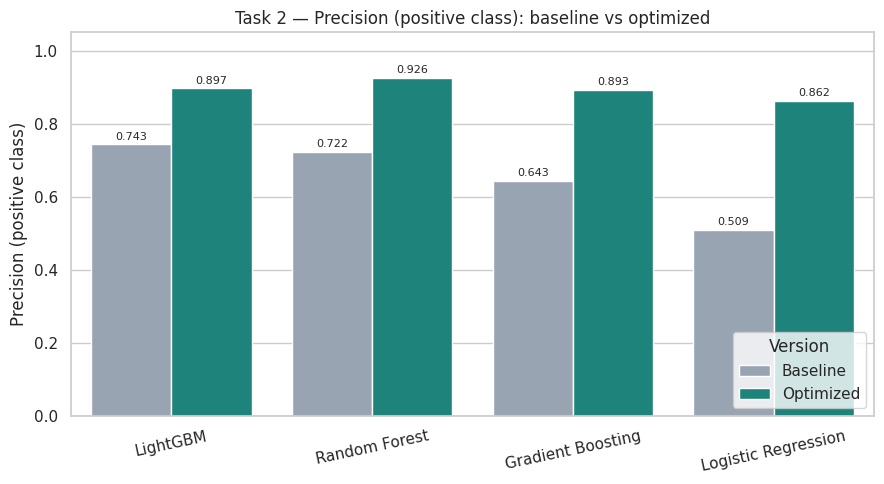

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/comparison_baseline_vs_optimized_recall.png


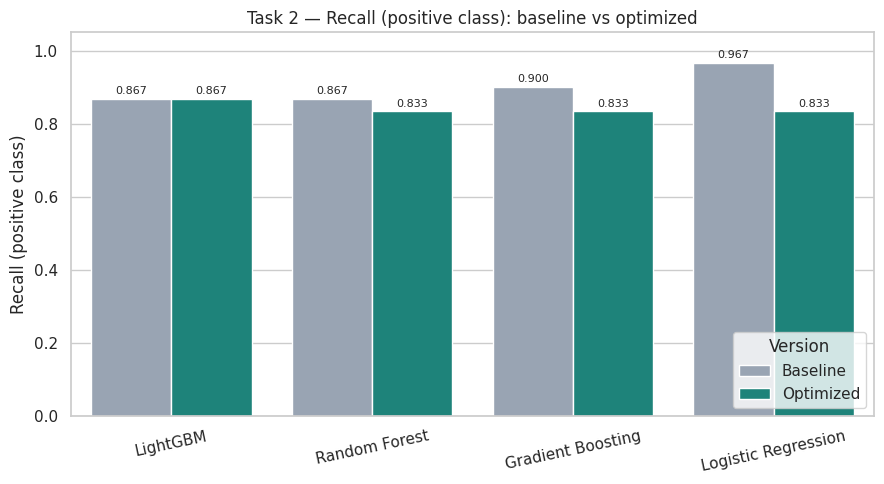

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/comparison_baseline_vs_optimized_f1_score.png


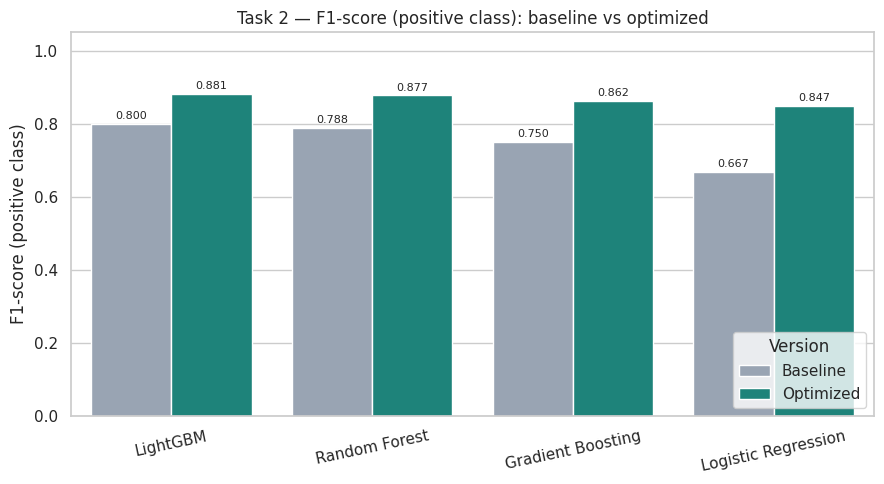

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/comparison_baseline_vs_optimized_roc_auc.png


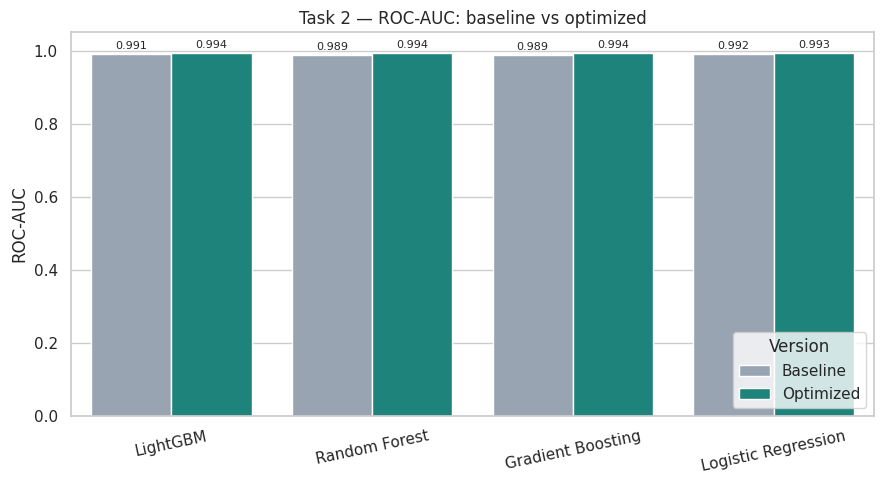

SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/comparison_baseline_vs_optimized_balanced_accuracy.png


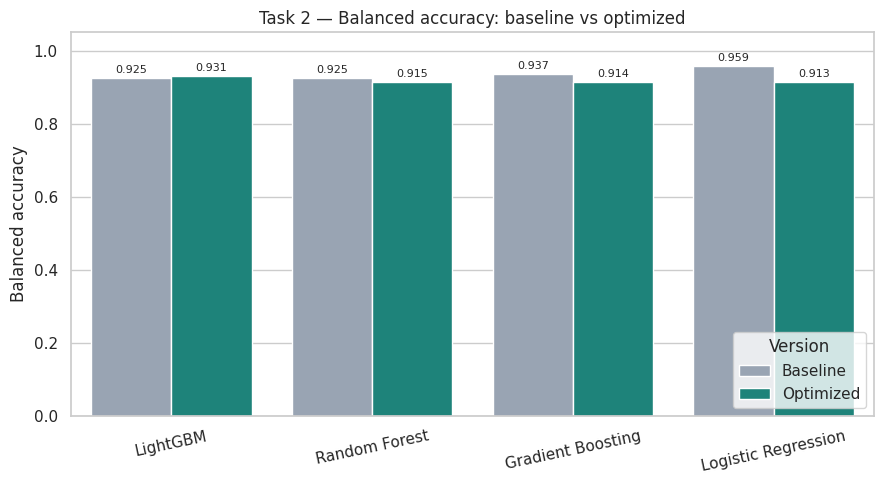

In [22]:
METRIC_LABELS = {
    "Precision": "Precision (positive class)",
    "Recall": "Recall (positive class)",
    "F1_Score": "F1-score (positive class)",
    "ROC_AUC": "ROC-AUC",
    "Balanced_Accuracy": "Balanced accuracy",
}
for metric, label in METRIC_LABELS.items():
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=comparison_df, x="Model", y=metric, hue="Stage",
                hue_order=["Baseline", "Optimized"],
                palette=["#94A3B8", "#0D9488"], ax=ax)
    ax.set(xlabel="", ylabel=label, title=f"Task 2 — {label}: baseline vs optimized", ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=12)
    for bar_container in ax.containers:
        ax.bar_label(bar_container, fmt="%.3f", padding=2, fontsize=8)
    ax.legend(title="Version", loc="lower right")
    plt.tight_layout()
    save_plot(f"comparison_baseline_vs_optimized_{metric.lower()}.png")
    plt.show()

## 22. Feature analysis - Random Forest, Gradient Boosting and LightGBM

Rank the top ten features for the three optimized tree ensembles. Each table and graph uses the **actual original numerical or derived semantic feature names**. Importance is model-dependent and descriptive, not evidence of causation.


Random Forest top ten optimized feature importances:


,Feature,Importance
0,SKILL_MATCH_SCORE,0.415789
1,JOB_EXP_MATCH_SCORE,0.373139
2,Job_Required_Criteria_Match_Ratio,0.030312
3,Job_Work_History_Jaccard_Score,0.025136
4,Max_Cosine,0.025038
5,Job_Experience_BM25_Score,0.023061
6,Communication_Skill_Score,0.019135
7,Applicant_Required_Criteria_Match_Ratio,0.016740
8,Job_Skills_Cosine,0.014506
9,Total_Job_History_Count,0.013216


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_feature_importance.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Random_Forest_feature_importance.png


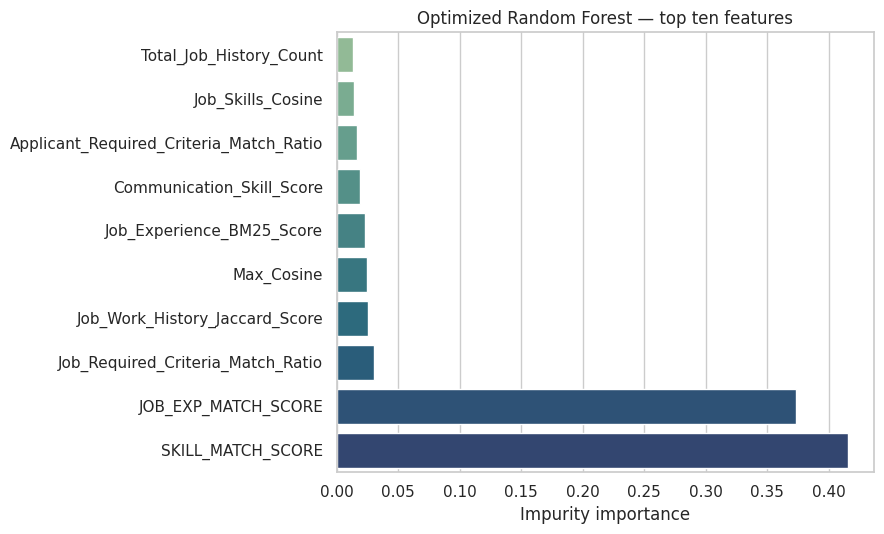


Gradient Boosting top ten optimized feature importances:


,Feature,Importance
0,JOB_EXP_MATCH_SCORE,0.486987
1,SKILL_MATCH_SCORE,0.386939
2,Job_Required_Criteria_Match_Ratio,0.038855
3,Max_Cosine,0.020837
4,Job_Work_History_Jaccard_Score,0.019118
5,Total_Job_History_Count,0.012776
6,Mean_Cosine,0.007996
7,Applicant_Required_Criteria_Match_Ratio,0.007600
8,Job_Skills_Cosine,0.006464
9,Job_Experience_BM25_Score,0.005192


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boosting_feature_importance.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Gradient_Boosting_feature_importance.png


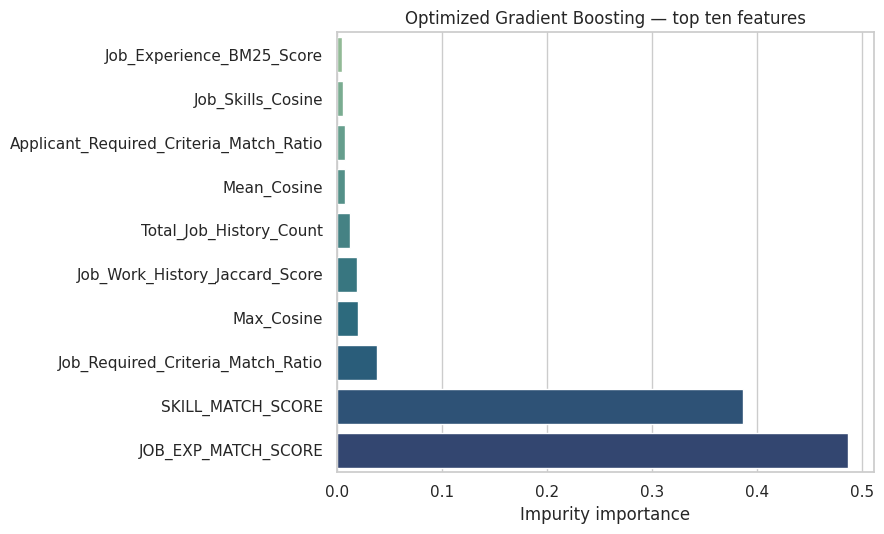


LightGBM top ten optimized feature importances:


,Feature,Importance
0,JOB_EXP_MATCH_SCORE,3666.980389
1,SKILL_MATCH_SCORE,2441.649363
2,Job_Required_Criteria_Match_Ratio,241.425191
3,Job_Work_History_Jaccard_Score,191.703088
4,Applicant_Required_Criteria_Match_Ratio,183.420890
5,Max_Cosine,170.517159
6,Mean_Cosine,96.550467
7,Total_Job_History_Count,89.787540
8,Job_Skills_Cosine,77.492329
9,Job_Experience_BM25_Score,74.179764


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_feature_importance.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_LightGBM_feature_importance.png


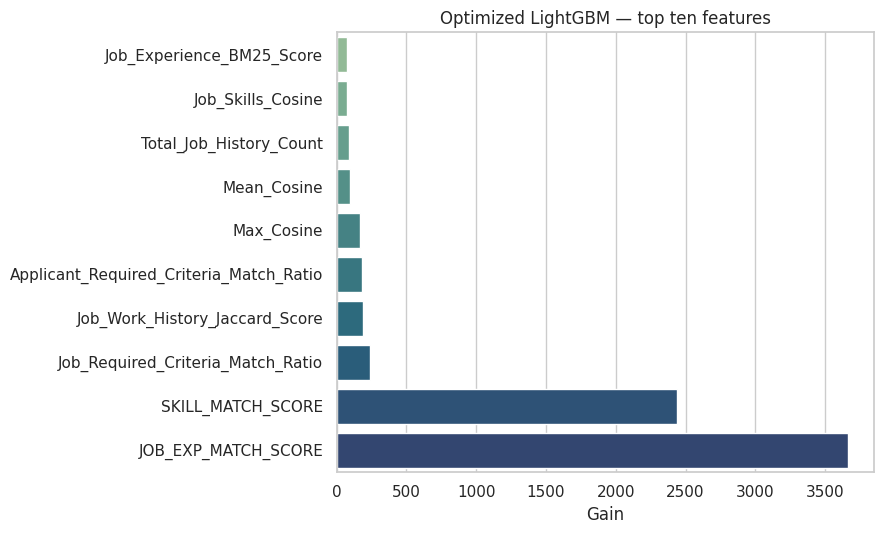

In [23]:
feature_importance_tables = {}
for model_name in ["Random Forest", "Gradient Boosting", "LightGBM"]:
    p = trained_pipelines[("Optimized", model_name)]
    prep = p.named_steps["preprocess"]
    est = p.named_steps["model"]
    feature_names = [v.split("__", 1)[-1] for v in prep.get_feature_names_out()]
    importances = np.asarray(est.feature_importances_, dtype=float)
    if len(feature_names) != len(importances):
        raise RuntimeError(f"Feature name / importance mismatch for {model_name}")
    values = pd.DataFrame({"Feature": feature_names, "Importance": importances})
    values = values.sort_values("Importance", ascending=False).reset_index(drop=True)
    feature_importance_tables[model_name] = values
    safe = model_name.replace(" ", "_")
    print(f"\n{model_name} top ten optimized feature importances:")
    display(values.head(10))
    save_csv(values, f"Optimized_{safe}_feature_importance.csv")
    top10 = values.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.barplot(data=top10, y="Feature", x="Importance", hue="Feature",
                dodge=False, palette="crest", legend=False, ax=ax)
    ax.set(xlabel=("Gain" if model_name == "LightGBM" else "Impurity importance"),
           ylabel="", title=f"Optimized {model_name} — top ten features")
    plt.tight_layout()
    save_plot(f"Optimized_{safe}_feature_importance.png")
    plt.show()

## 23. Logistic Regression coefficient directions

Coefficients can be positive or negative. Since its 16 numerical inputs are standardized inside the pipeline, each coefficient describes a one-standard-deviation change in the feature with other features held fixed. Because features are correlated (especially the three aggregate semantic similarities), individual coefficients should be interpreted cautiously.

,Feature,Coefficient,Direction,Absolute_Coefficient
0,SKILL_MATCH_SCORE,1.636508,Positive,1.636508
1,JOB_EXP_MATCH_SCORE,1.619552,Positive,1.619552
2,Applicant_Required_Criteria_Match_Ratio,-0.361919,Negative,0.361919
3,Job_Work_History_Jaccard_Score,0.312163,Positive,0.312163
4,Max_Cosine,-0.271700,Negative,0.271700
5,Job_Required_Criteria_Match_Ratio,0.231921,Positive,0.231921
6,Min_Cosine,-0.215604,Negative,0.215604
7,Job_Skills_Cosine,0.166789,Positive,0.166789
8,Job_History_Count_Last_3_Years,-0.153607,Negative,0.153607
9,Total_Job_History_Count,-0.126435,Negative,0.126435


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Logistic_Regression_coefficients.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Optimized_Logistic_Regression_coefficients.png


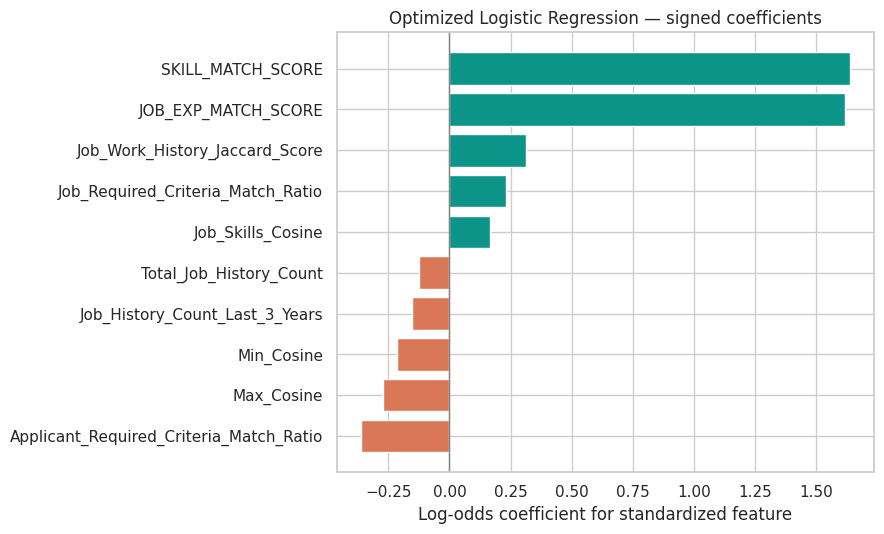

In [24]:
p = trained_pipelines[("Optimized", "Logistic Regression")]
prep = p.named_steps["preprocess"]
clf = p.named_steps["model"]
names = [v.split("__", 1)[-1] for v in prep.get_feature_names_out()]
coefs = np.asarray(clf.coef_[0], dtype=float)
if len(names) != len(coefs):
    raise RuntimeError("Logistic Regression coefficient/feature count mismatch")
lr_coefficients = pd.DataFrame({
    "Feature": names, "Coefficient": coefs,
    "Direction": np.where(coefs > 0, "Positive", np.where(coefs < 0, "Negative", "Zero")),
    "Absolute_Coefficient": np.abs(coefs),
}).sort_values("Absolute_Coefficient", ascending=False).reset_index(drop=True)
display(lr_coefficients)
save_csv(lr_coefficients, "Optimized_Logistic_Regression_coefficients.csv")

subset = lr_coefficients.head(10).sort_values("Coefficient")
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = np.where(subset["Coefficient"] >= 0, "#0D9488", "#D97757")
ax.barh(subset["Feature"], subset["Coefficient"], color=colors)
ax.axvline(0, color="gray", lw=1)
ax.set(xlabel="Log-odds coefficient for standardized feature", ylabel="",
       title="Optimized Logistic Regression — signed coefficients")
plt.tight_layout()
save_plot("Optimized_Logistic_Regression_coefficients.png")
plt.show()

## 24. How much feature importance comes from semantic similarities?

For each optimized tree model, report the share of its **within-model total importance** assigned to the six semantic features versus the ten original numerical features. These are relative summaries, not causal effects; do not compare raw importance magnitudes *across different algorithms*.

,Model,Feature_Group,Importance_Sum,Share_Percent
0,Random Forest,Original numerical (10),0.928266,92.826649
1,Random Forest,MiniLM similarity (6),0.071734,7.173351
2,Gradient Boosting,Original numerical (10),0.958855,95.885492
3,Gradient Boosting,MiniLM similarity (6),0.041145,4.114508
4,LightGBM,Original numerical (10),7037.164388,94.171613
5,LightGBM,MiniLM similarity (6),435.538020,5.828387


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_vs_numeric_feature_importance_shares.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/semantic_vs_numeric_importance_shares.png


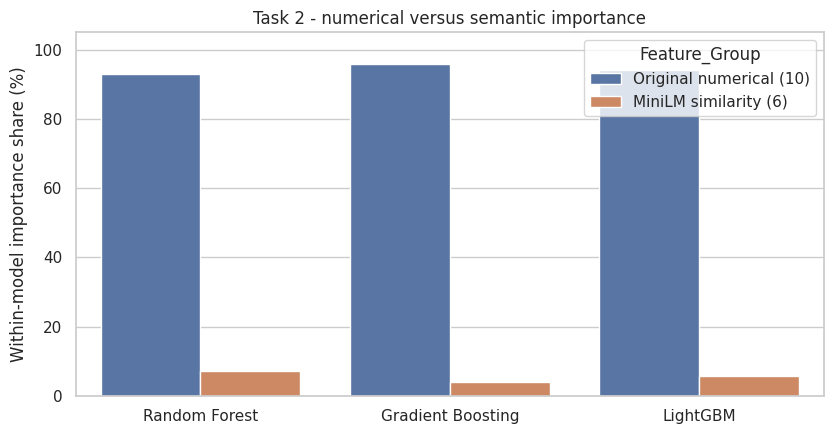

In [25]:
source_share_rows = []
for model_name, table in feature_importance_tables.items():
    total = float(table["Importance"].sum())
    for origin, items in [
        ("Original numerical (10)", NUMERIC_FEATURES),
        ("MiniLM similarity (6)", SEMANTIC_FEATURES),
    ]:
        subtotal = float(table.loc[table["Feature"].isin(items), "Importance"].sum())
        source_share_rows.append({
            "Model": model_name,
            "Feature_Group": origin,
            "Importance_Sum": subtotal,
            "Share_Percent": 100 * subtotal / total if total > 0 else np.nan,
        })

origin_shares = pd.DataFrame(source_share_rows)
display(origin_shares)
save_csv(origin_shares, "semantic_vs_numeric_feature_importance_shares.csv")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=origin_shares, x="Model", y="Share_Percent", hue="Feature_Group", ax=ax)
ax.set(xlabel="", ylabel="Within-model importance share (%)",
       title="Task 2 - numerical versus semantic importance", ylim=(0, 105))
plt.tight_layout()
save_plot("semantic_vs_numeric_importance_shares.png")
plt.show()

## 25. Optional comparison with the saved Task 1 experiment

If you previously executed the Task 1 optimized notebook, this cell loads its saved metrics **only when the original dataset hash and held-out test row indices match**. It compares Task 1 (10 numeric features) with Task 2 (10 numeric + 6 semantic similarities). If those files are unavailable or do not match, it skips the comparison without affecting Task 2.

VALIDATED: same source CSV SHA-256 and test row indices.


,Model,Task_1_F1,Task_1_Precision,Task_1_Recall,Task_2_F1,Task_2_Precision,Task_2_Recall,Task_2_minus_Task_1_F1
0,Logistic Regression,0.866667,0.866667,0.866667,0.847458,0.862069,0.833333,-0.019209
1,Gradient Boosting,0.830769,0.771429,0.900000,0.862069,0.892857,0.833333,0.031300
2,Random Forest,0.827586,0.857143,0.800000,0.877193,0.925926,0.833333,0.049607
3,LightGBM,0.800000,0.880000,0.733333,0.881356,0.896552,0.866667,0.081356


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Task_1_vs_Task_2_optimized_comparison.csv
SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Task_1_vs_Task_2_f1_comparison.png


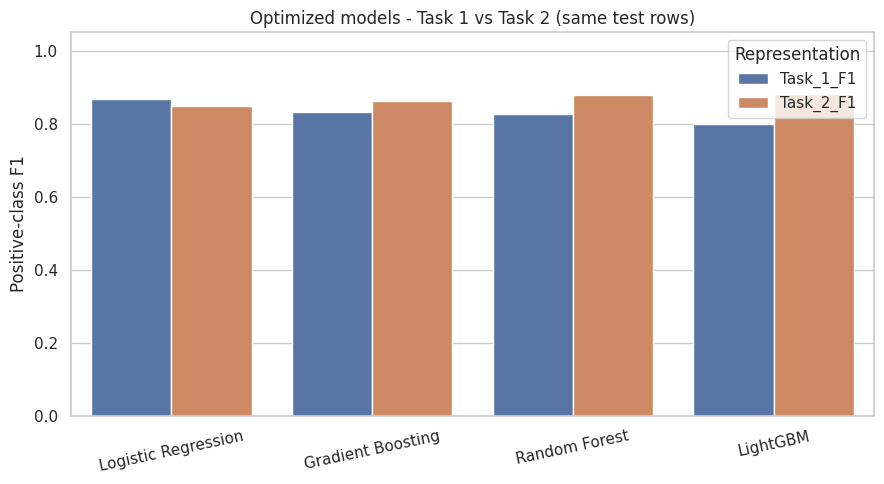

In [26]:
TASK1_RESULTS_DIR = (
    Path("/content/drive/MyDrive/Recruitment_Internship_Project/Task_1_Optimized_Results")
    if IS_COLAB else Path("/mnt/data/Task_1_Optimized_Results")
)
task1_paired_file = TASK1_RESULTS_DIR / "all_baseline_and_optimized_test_metrics.csv"
task1_test_rows_file = TASK1_RESULTS_DIR / "test_row_indices.csv"
task1_audit_file = TASK1_RESULTS_DIR / "data_audit_summary.json"

comparison_allowed = all(p.exists() for p in [task1_paired_file, task1_test_rows_file, task1_audit_file])
if comparison_allowed:
    with open(task1_audit_file, "r", encoding="utf-8") as f:
        task1_audit = json.load(f)
    task1_split = pd.read_csv(task1_test_rows_file)
    same_input = task1_audit.get("data_sha256") == current_sha
    same_rows = np.array_equal(
        np.sort(task1_split["Original_Row_Index"].to_numpy()),
        np.sort(X_test.index.to_numpy()),
    )
    comparison_allowed = same_input and same_rows
    if not comparison_allowed:
        print("Skipping Task 1 comparison: dataset fingerprint or test rows differ.")

if comparison_allowed:
    task1_metrics = pd.read_csv(task1_paired_file)
    subset = task1_metrics.loc[task1_metrics["Stage"] == "Optimized", ["Model", "F1_Score", "Precision", "Recall"]].copy()
    subset = subset.rename(columns={"F1_Score": "Task_1_F1", "Precision": "Task_1_Precision", "Recall": "Task_1_Recall"})
    task2_metrics = comparison_df.loc[comparison_df["Stage"] == "Optimized", ["Model", "F1_Score", "Precision", "Recall"]].copy()
    task2_metrics = task2_metrics.rename(columns={"F1_Score": "Task_2_F1", "Precision": "Task_2_Precision", "Recall": "Task_2_Recall"})
    cross_task = subset.merge(task2_metrics, on="Model", validate="one_to_one")
    cross_task["Task_2_minus_Task_1_F1"] = cross_task["Task_2_F1"] - cross_task["Task_1_F1"]
    print("VALIDATED: same source CSV SHA-256 and test row indices.")
    display(cross_task)
    save_csv(cross_task, "Task_1_vs_Task_2_optimized_comparison.csv")
    fig, ax = plt.subplots(figsize=(9, 5))
    melted = cross_task.melt(id_vars="Model", value_vars=["Task_1_F1", "Task_2_F1"], var_name="Representation", value_name="F1")
    sns.barplot(data=melted, x="Model", y="F1", hue="Representation", ax=ax)
    ax.set(ylim=(0, 1.05), ylabel="Positive-class F1", xlabel="", title="Optimized models - Task 1 vs Task 2 (same test rows)")
    ax.tick_params(axis="x", rotation=12)
    plt.tight_layout()
    save_plot("Task_1_vs_Task_2_f1_comparison.png")
    plt.show()
else:
    print("Task 1 results unavailable or incompatible. Task 2 is fully standalone; skipping optional comparison.")

## 26. Automatically export a standalone HTML results report

This creates a **self-contained HTML report** that can be opened or shared without Python, Google Colab, installed packages, or a running notebook. It embeds the actual evaluation tables and selected figures directly in the HTML file. It is saved to the same output folder and included in the final ZIP. All numbers are taken from computed results, not manually typed.

In [27]:
# Portable HTML report: includes actual results and embeds saved PNG files as data URLs.
import base64
from html import escape as html_escape


def embedded_figure(filename, caption):
    image_path = OUTPUT_DIR / filename
    if not image_path.is_file():
        return ""
    encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
    return (f'<figure><img src="data:image/png;base64,{encoded}" '
            f'alt="{html_escape(caption)}" />'
            f'<figcaption>{html_escape(caption)}</figcaption></figure>')


figure_list = [
    ("original_class_pie.png", "Original 5% positive-class imbalance"),
    ("five_fold_cv_diagram.png", "Five-fold cross-validation illustration"),
    ("oversampling_before_after.png", "Training-only random oversampling"),
    ("semantic_feature_distributions.png", "Six multilingual semantic similarity features"),
    ("semantic_feature_correlation.png", "Correlations between semantic features"),
    ("training_cv_baseline_vs_optimized.png", "Training-only selection metrics"),
    ("comparison_baseline_vs_optimized_f1_score.png", "Test F1: baseline vs optimized"),
    ("comparison_baseline_vs_optimized_precision.png", "Test positive-class precision"),
    ("comparison_baseline_vs_optimized_recall.png", "Test positive-class recall"),
    ("optimized_combined_roc_curves.png", "ROC curves for the four optimized classifiers"),
    ("semantic_vs_numeric_importance_shares.png", "Numerical and semantic feature importance"),
    ("Optimized_Logistic_Regression_coefficients.png", "Logistic Regression feature coefficient signs"),
]
for model_slug in ["Random_Forest", "Gradient_Boosting", "LightGBM"]:
    figure_list.append((f"Optimized_{model_slug}_feature_importance.png",
                        f"Optimized {model_slug.replace('_', ' ')} feature importance"))
for model_slug in ["Logistic_Regression", "Random_Forest", "Gradient_Boosting", "LightGBM"]:
    figure_list.append((f"Optimized_{model_slug}_confusion_matrix.png",
                        f"Optimized {model_slug.replace('_', ' ')} confusion matrix"))
if (OUTPUT_DIR / "Task_1_vs_Task_2_f1_comparison.png").is_file():
    figure_list.append(("Task_1_vs_Task_2_f1_comparison.png", "Task 1 vs Task 2: identical test records"))

styles = """
body{font:15px/1.65 Arial,sans-serif;max-width:1000px;margin:auto;padding:35px;color:#1f2937}
h1,h2{color:#0f3a55} h1{border-bottom:3px solid #0d9488;padding-bottom:12px}
table{border-collapse:collapse;width:100%;margin:18px 0;font-size:13px}
th,td{border:1px solid #d9e1e8;padding:8px 9px;text-align:left}
th{background:#e9f1f5} tr:nth-child(even){background:#f8fafc}
figure{margin:28px auto;text-align:center;page-break-inside:avoid}
img{max-width:95%;height:auto;border:1px solid #e5e7eb;border-radius:6px}
figcaption{color:#475569;font-size:13px} .note{background:#f1f5f9;padding:14px;border-left:4px solid #0d9488}
"""
summary_table_html = comparison_df.to_html(index=False, escape=True,
                                            float_format=lambda v: f"{v:.4f}")
selected_table_html = selected_df[["Model", "Strategy", "Threshold", "OOF_Selection_F1"]].to_html(
    index=False, escape=True, float_format=lambda v: f"{v:.4f}")
importance_table_html = origin_shares.to_html(index=False, escape=True,
                                              float_format=lambda v: f"{v:.3f}")
body_parts = [
    '<h1>Task 2 - Optimized Numerical + Semantic Recruitment Matching</h1>',
    '<div class="note">This document was generated automatically from a real notebook run. '
    'F1 is evaluated for positive matches (label 1). This synthetic, row-level split is exploratory.</div>',
    f'<p><strong>Dataset:</strong> {len(df):,} records; '
    f'{int((y_all==1).sum()):,} positive / {int((y_all==0).sum()):,} negative. '
    f'<strong>Training:</strong> {len(X_train):,}; <strong>Test:</strong> {len(X_test):,}.</p>',
    '<p><strong>Text fields:</strong> Job, Choice Point, Skills (original Japanese). '
    'Pretrained multilingual MiniLM encodes each into 384 numerical dimensions. '
    'A cosine similarity compares the directions of two normalized vectors: '
    'cos(A,B) = dot(A,B) / (length(A) * length(B)). '
    'Three pairwise scores + mean, maximum and minimum = six derived similarities. '
    'Together with ten original numerical features: <strong>16 model features</strong>.</p>',
    '<h2>Selected optimization settings (training-only)</h2>', selected_table_html,
    '<h2>Final held-out test metrics - baseline and optimized</h2>', summary_table_html,
    '<h2>Semantic vs numerical feature importance</h2>', importance_table_html,
    '<h2>Figures</h2>',
]
body_parts.extend(embedded_figure(file, caption) for file, caption in figure_list)
body_parts.append("<h2>Research limitations</h2><p>Identity overlap between training and testing; "
                  "small positive test class; synthetic target generation and possible engineered-feature leakage; "
                  "optimistic model-selection cross-validation; previous inspections of this dataset. "
                  "The pretrained text encoder was frozen. Importance measures predictiveness rather than causality. "
                  "Evaluate new group-disjoint cases before deployment.</p>")
report_html = ("<!doctype html><html lang='en'><head><meta charset='utf-8'>"
               "<meta name='viewport' content='width=device-width,initial-scale=1'>"
               "<title>Task 2 Internship Results</title><style>" + styles +
               "</style></head><body>" + "\n".join(body_parts) + "</body></html>")
html_path = OUTPUT_DIR / "Task_2_Complete_Results_Report.html"
html_path.write_text(report_html, encoding="utf-8")
print("SAVED standalone report:", html_path)
print("Embedded figure count:", sum(bool((OUTPUT_DIR / fname).is_file()) for fname, _ in figure_list))


SAVED standalone report: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/Task_2_Complete_Results_Report.html
Embedded figure count: 20


## 27. Final Task 2 internship summary and saved-file inventory

Summarize the actual source data, pretrained semantic encoder, feature fusion, five-fold validation, balancing strategies, selected thresholds, test performance and feature importance. The model comparisons, plots, saved pipelines and raw evaluation records are exported to the dedicated output folder. No result is typed in manually; metrics are computed from fitted predictions.

In [28]:
best_training_model = str(selected_df.sort_values("OOF_Selection_F1", ascending=False).iloc[0]["Model"])
best_observed_test_model = str(comparison_df.query("Stage == 'Optimized'").sort_values("F1_Score", ascending=False).iloc[0]["Model"])
print("=" * 76)
print("TASK 2 - COMPLETE INTERNSHIP PROJECT SUMMARY")
print("=" * 76)
print(f"Dataset: {len(df):,} rows; original columns: {len(raw_df.columns)}; "
      f"Task 2 features: {len(TASK2_FEATURES)}")
print(f"Original classes: {(y_all == 0).sum():,} negative, {(y_all == 1).sum():,} positive")
print("Text fields:", TEXT_COLUMNS)
print("Frozen pretrained semantic encoder:", ENCODER_MODEL)
print("Embedding dimensions per original text field: 384")
print("Features: 10 original numerical + 6 cosine similarity = 16")
print(f"Split: {len(X_train):,} train / {len(X_test):,} test, 80/20 stratified, seed {RANDOM_STATE}")
print("Preprocessing: median imputation; Logistic Regression scaling; optional categorical encoding")
print("Baseline: RandomOverSampler ratio 1.0; threshold 0.50")
print(f"Optimization: {N_SEARCH_PER_MODEL} randomized parameter sets x "
      f"{len(BALANCE_STRATEGIES)} balancing strategies x 5 stratified folds")
print("Imbalance options:", ", ".join(BALANCE_STRATEGIES))
print("Threshold selected from 0.05 to 0.95 on training-only OOF probabilities")
print("Models:", ", ".join(MODEL_DEFINITIONS))
print("\nFINAL TEST RESULTS:")
print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nCV-selected candidate: {best_training_model}")
print(f"Highest observed optimized test F1: {best_observed_test_model}")
print("\nTop five features for the CV-selected optimized model:")
if best_training_model in feature_importance_tables:
    print(feature_importance_tables[best_training_model].head(5).to_string(index=False))
else:
    print(lr_coefficients[["Feature", "Coefficient", "Direction"]].head(5).to_string(index=False))
print("\nLIMITATIONS:")
print("- Synthetic labels; engineered matching scores could overlap label construction")
print("- Repeated Recruitment_ID and Applicant_ID can cross row-level split")
print("- Only 30 positive records in the 600-row test split")
print("- Similarities are derived from a pretrained encoder, not fine-tuned on labels")
print("- OOF selection F1 optimistic from threshold/model selection")
print("- Previously inspected test sets: confirm with genuinely independent group-disjoint data")
print("- More semantic features do not guarantee higher F1")

save_json({
    "project": "Task 2 - numerical plus pretrained multilingual MiniLM cosine similarities",
    "dataset_path": str(dataset_path),
    "data_sha256": current_sha,
    "dataset_rows": len(df),
    "num_features": len(TASK2_FEATURES),
    "numeric_features": NUMERIC_FEATURES,
    "semantic_features": SEMANTIC_FEATURES,
    "text_columns": TEXT_COLUMNS,
    "pretrained_encoder": ENCODER_MODEL,
    "embedding_dimensions": 384,
    "features_used_by_classifiers": TASK2_FEATURES,
    "target": TARGET_COLUMN,
    "positive_label": POSITIVE_CLASS,
    "original_class_counts": {"negative": int((y_all == 0).sum()), "positive": int((y_all == 1).sum())},
    "split": {"method": "Stratified train_test_split", "test_fraction": TEST_SIZE,
              "random_state": RANDOM_STATE, "train_rows": len(X_train), "test_rows": len(X_test)},
    "baseline_oversampling_ratio": OVERSAMPLING_RATIO,
    "tuning": {"candidate_parameter_sets_per_model": N_SEARCH_PER_MODEL,
               "imbalance_strategies": BALANCE_STRATEGIES,
               "cv": "StratifiedKFold(5, shuffle=True, random_state=42)",
               "threshold_grid_min": float(THRESHOLDS.min()),
               "threshold_grid_max": float(THRESHOLDS.max())},
    "selected_configs": selected_config,
    "cv_selected_model": best_training_model,
    "highest_observed_optimized_test_f1_model": best_observed_test_model,
    "final_model_metrics": comparison_df.to_dict(orient="records"),
    "limitations": ["synthetic labels/engineered-feature target leakage", "overlapping IDs",
                    "small positive test sample", "optimistic OOF selection",
                    "prior test-set inspections"],
}, "final_project_summary.json")

inventory = pd.DataFrame([
    {"Filename": f.name, "Size_KB": round(f.stat().st_size / 1024, 2), "Full_Path": str(f.resolve())}
    for f in sorted(OUTPUT_DIR.iterdir()) if f.is_file()
])
display(inventory)
save_csv(inventory, "saved_files_inventory.csv")
archive_base = OUTPUT_DIR.parent / "Task_2_Optimized_Results"
archive_path = shutil.make_archive(str(archive_base), "zip", root_dir=str(OUTPUT_DIR.parent),
                                   base_dir=OUTPUT_DIR.name)
print("\nALL RESULTS SAVED IN:", OUTPUT_DIR.resolve())
print("ZIP ARCHIVE SAVED TO:", archive_path)
print("\nTo make results visible in a downloaded notebook: File > Save, "
      "verify success, then File > Download > Download .ipynb.")

TASK 2 - COMPLETE INTERNSHIP PROJECT SUMMARY
Dataset: 3,000 rows; original columns: 16; Task 2 features: 16
Original classes: 2,850 negative, 150 positive
Text fields: ['Job', 'Choice Point', 'Skills']
Frozen pretrained semantic encoder: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Embedding dimensions per original text field: 384
Features: 10 original numerical + 6 cosine similarity = 16
Split: 2,400 train / 600 test, 80/20 stratified, seed 42
Preprocessing: median imputation; Logistic Regression scaling; optional categorical encoding
Baseline: RandomOverSampler ratio 1.0; threshold 0.50
Optimization: 8 randomized parameter sets x 3 balancing strategies x 5 stratified folds
Imbalance options: none, oversample_0.5, oversample_1.0
Threshold selected from 0.05 to 0.95 on training-only OOF probabilities
Models: Logistic Regression, Random Forest, Gradient Boosting, LightGBM

FINAL TEST RESULTS:
    Stage               Model  Precision  Recall  F1_Score  ROC_AUC  Balanced_Ac

,Filename,Size_KB,Full_Path
0,Baseline_Gradient_Boosting_classification_repo...,0.30,/content/drive/MyDrive/Recruitment_Internship_...
1,Baseline_Gradient_Boosting_classification_repo...,0.32,/content/drive/MyDrive/Recruitment_Internship_...
2,Baseline_Gradient_Boosting_confusion_matrix.csv,0.11,/content/drive/MyDrive/Recruitment_Internship_...
3,Baseline_Gradient_Boosting_confusion_matrix.png,47.34,/content/drive/MyDrive/Recruitment_Internship_...
4,Baseline_Gradient_Boosting_roc_curve.csv,3.35,/content/drive/MyDrive/Recruitment_Internship_...
...,...,...,...
126,test_row_indices.csv,3.93,/content/drive/MyDrive/Recruitment_Internship_...
127,train_row_indices.csv,15.55,/content/drive/MyDrive/Recruitment_Internship_...
128,train_test_class_counts.csv,0.07,/content/drive/MyDrive/Recruitment_Internship_...
129,train_test_split_audit.json,0.22,/content/drive/MyDrive/Recruitment_Internship_...


SAVED: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results/saved_files_inventory.csv

ALL RESULTS SAVED IN: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results
ZIP ARCHIVE SAVED TO: /content/drive/MyDrive/Recruitment_Internship_Project/Task_2_Optimized_Results.zip

To make results visible in a downloaded notebook: File > Save, verify success, then File > Download > Download .ipynb.


## 28. Sharing and rerunning the completed Task 2 notebook

- **To generate real optimized results:** Run all cells **once in Google Colab**, with the original CSV accessible. The notebook reuses verified earlier real MiniLM similarities from Drive if available; otherwise it runs the pretrained model in Colab.
- **To view/share results after execution:** Save and download the executed `.ipynb` file. Its outputs are visible without rerunning; trained `.joblib` model files remain separate.
- **To save additional deliverables:** Take the generated `Task_2_Optimized_Results.zip` from the same Google Drive project folder. It contains every plot, score table, optimization search, fitted model, prediction and feature-analysis CSV.
- **To compare fairly:** The optional Task 1 comparison checks the input SHA-256 and exact test row IDs; do not compare arbitrary splits.
- **Research caution:** The dataset is synthetic and the requested row-level stratification permits repeated recruitment/applicant identities. Treat results as exploratory; independently validate group-disjoint and real-world cases before deployment.